In [1]:
# ============================================================
# CELL 1 — EMOBERTA-BASE + SELECTIVE
# ============================================================

import os
import re
import gc
import json
import html
import random
import warnings

import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_NAME = "tae898/emoberta-base"
EXPERIMENT_NAME = "EmoBERTa-base + Selective"
CLEANING_METHOD = "Selective"

MAX_LENGTH = 512
METADATA_DIM = 53
FREEZE_TRANSFORMER = True

BASE_RESULT_DIR = "/kaggle/working/emoberta_selective"

RESULT_DIR = os.path.join(
    BASE_RESULT_DIR,
    "results"
)

CHECKPOINT_DIR = os.path.join(
    BASE_RESULT_DIR,
    "checkpoints"
)

BACKUP_DIR = os.path.join(
    BASE_RESULT_DIR,
    "backup"
)

for directory in [
    RESULT_DIR,
    CHECKPOINT_DIR,
    BACKUP_DIR
]:
    os.makedirs(
        directory,
        exist_ok=True
    )

FIXED_CONTROLS = {
    "user_level_split": True,
    "train_users": 6135,
    "validation_users": 767,
    "test_users": 767,
    "diagnostic_anchor_removal": True,
    "metadata_features": 53,
    "metadata_scaling": "TRAIN ONLY",
    "training_balance": "2013 negative + 2013 positive",
    "batch_size": 16,
    "context_length": 512,
    "random_seed": 42,
    "checkpoint_metric": "Validation F1",
    "early_stopping_patience": 2,
    "maximum_epochs": 10,
    "transformer_frozen": True
}

print("=" * 60)
print("EMOBERTA-BASE + SELECTIVE")
print("=" * 60)

print()
print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )
    print(
        "CUDA:",
        torch.version.cuda
    )

print()
print("Model:", MODEL_NAME)
print("Cleaning:", CLEANING_METHOD)
print("Context length:", MAX_LENGTH)
print("Metadata features:", METADATA_DIM)
print("Transformer frozen:", FREEZE_TRANSFORMER)
print("Seed:", SEED)

print()
print("=" * 60)
print("SELECTIVE CLEANING POLICY")
print("=" * 60)

print("01. Remove URLs")
print("02. Remove malformed URL variants")
print("03. Remove user mentions")
print("04. Remove hashtag symbols")
print("05. Remove HTML / markup")
print("06. Preserve normal punctuation")
print("07. Preserve emojis")
print("08. Preserve emoticons")
print("09. Preserve expressive symbols where applicable")
print("10. Normalize unnecessary whitespace")
print("11. Lowercase text")

print()
print("=" * 60)
print("EMOBERTA CONFIGURATION")
print("=" * 60)

print("Base encoder: EmoBERTa-base")
print("Pretrained model:", MODEL_NAME)
print("Backbone training: FROZEN")
print("Downstream classifier: TRAINABLE")
print("Metadata branch: TRAINABLE")

experiment_config = {
    "experiment_name": EXPERIMENT_NAME,
    "model_name": MODEL_NAME,
    "cleaning_method": CLEANING_METHOD,
    "context_length": MAX_LENGTH,
    "metadata_dimension": METADATA_DIM,
    "transformer_frozen": FREEZE_TRANSFORMER,
    "seed": SEED,
    "fixed_controls": FIXED_CONTROLS
}

with open(
    os.path.join(
        RESULT_DIR,
        "experiment_config.json"
    ),
    "w"
) as f:
    json.dump(
        experiment_config,
        f,
        indent=2
    )

print()
print("=" * 60)
print("CELL 1 COMPLETE")
print("=" * 60)

print("✓ EmoBERTa-base selected")
print("✓ Selective cleaning selected")
print("✓ Context length = 512")
print("✓ Metadata dimension = 53")
print("✓ Transformer backbone = FROZEN")
print("✓ Downstream layers = TRAINABLE")
print("✓ Random seed = 42")
print("✓ Result directory created")
print("✓ Checkpoint directory created")
print("✓ Backup directory created")
print("✓ Experiment configuration saved")
print("✓ Previous experiment outputs untouched")
print("✓ Fixed experimental controls recorded")

EMOBERTA-BASE + SELECTIVE

Device: cuda
GPU: Tesla T4
CUDA: 12.8

Model: tae898/emoberta-base
Cleaning: Selective
Context length: 512
Metadata features: 53
Transformer frozen: True
Seed: 42

SELECTIVE CLEANING POLICY
01. Remove URLs
02. Remove malformed URL variants
03. Remove user mentions
04. Remove hashtag symbols
05. Remove HTML / markup
06. Preserve normal punctuation
07. Preserve emojis
08. Preserve emoticons
09. Preserve expressive symbols where applicable
10. Normalize unnecessary whitespace
11. Lowercase text

EMOBERTA CONFIGURATION
Base encoder: EmoBERTa-base
Pretrained model: tae898/emoberta-base
Backbone training: FROZEN
Downstream classifier: TRAINABLE
Metadata branch: TRAINABLE

CELL 1 COMPLETE
✓ EmoBERTa-base selected
✓ Selective cleaning selected
✓ Context length = 512
✓ Metadata dimension = 53
✓ Transformer backbone = FROZEN
✓ Downstream layers = TRAINABLE
✓ Random seed = 42
✓ Result directory created
✓ Checkpoint directory created
✓ Backup directory created
✓ Experime

In [2]:
# ============================================================
# CELL 2 — EMOBERTA-BASE + SELECTIVE
# ============================================================

print("=" * 60)
print("EMOBERTA-BASE + SELECTIVE — LOADING EXACT USER-LEVEL SPLIT")
print("=" * 60)

SPLIT_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "mddl-experiment-1-splits"
)

TRAIN_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_train_raw.pkl"
)

VAL_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_val_raw.pkl"
)

TEST_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_test_raw.pkl"
)

print()
print("TRAIN:", TRAIN_PATH)
print("VAL:  ", VAL_PATH)
print("TEST: ", TEST_PATH)

assert os.path.exists(TRAIN_PATH)
assert os.path.exists(VAL_PATH)
assert os.path.exists(TEST_PATH)

print()
print("✓ All split files found")

train_df = pd.read_pickle(
    TRAIN_PATH
)

val_df = pd.read_pickle(
    VAL_PATH
)

test_df = pd.read_pickle(
    TEST_PATH
)

print()
print("=" * 60)
print("SPLIT SHAPES")
print("=" * 60)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

assert train_df.shape == (6135, 82)
assert val_df.shape == (767, 82)
assert test_df.shape == (767, 82)

print()
print("=" * 60)
print("REQUIRED COLUMN CHECK")
print("=" * 60)

required_columns = [
    "user_id",
    "username",
    "label",
    "timeline_text"
]

for column in required_columns:

    assert column in train_df.columns
    assert column in val_df.columns
    assert column in test_df.columns

    print("✓", column)

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

train_users = set(
    train_df["user_id"]
)

val_users = set(
    val_df["user_id"]
)

test_users = set(
    test_df["user_id"]
)

print(
    "Train unique users:",
    train_df["user_id"].nunique()
)

print(
    "Validation unique users:",
    val_df["user_id"].nunique()
)

print(
    "Test unique users:",
    test_df["user_id"].nunique()
)

assert train_df["user_id"].is_unique
assert val_df["user_id"].is_unique
assert test_df["user_id"].is_unique

print(
    "TRAIN ↔ VAL:",
    len(train_users & val_users)
)

print(
    "TRAIN ↔ TEST:",
    len(train_users & test_users)
)

print(
    "VAL ↔ TEST:",
    len(val_users & test_users)
)

assert len(train_users & val_users) == 0
assert len(train_users & test_users) == 0
assert len(val_users & test_users) == 0

print()
print("✓ No duplicate users")
print("✓ No cross-split overlap")

print()
print("=" * 60)
print("LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(
    train_df["label"]
    .value_counts()
    .sort_index()
)

print()
print("VALIDATION:")
print(
    val_df["label"]
    .value_counts()
    .sort_index()
)

print()
print("TEST:")
print(
    test_df["label"]
    .value_counts()
    .sort_index()
)

assert (
    train_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {
        0: 4122,
        1: 2013
    }
)

assert (
    val_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {
        0: 515,
        1: 252
    }
)

assert (
    test_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {
        0: 516,
        1: 251
    }
)

print()
print("=" * 60)
print("TIMELINE TEXT CHECK")
print("=" * 60)

train_null = int(
    train_df["timeline_text"]
    .isna()
    .sum()
)

val_null = int(
    val_df["timeline_text"]
    .isna()
    .sum()
)

test_null = int(
    test_df["timeline_text"]
    .isna()
    .sum()
)

print(
    "TRAIN null timeline texts:",
    train_null
)

print(
    "VALIDATION null timeline texts:",
    val_null
)

print(
    "TEST null timeline texts:",
    test_null
)

assert train_null == 0
assert val_null == 0
assert test_null == 0

print()
print("=" * 60)
print("CELL 2 COMPLETE")
print("=" * 60)

print("✓ Exact user-level split restored")
print("✓ TRAIN = 6135")
print("✓ VALIDATION = 767")
print("✓ TEST = 767")
print("✓ Same labels as previous experiments")
print("✓ No duplicate users")
print("✓ No cross-split user overlap")
print("✓ Timeline text available")

EMOBERTA-BASE + SELECTIVE — LOADING EXACT USER-LEVEL SPLIT

TRAIN: /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_train_raw.pkl
VAL:   /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_val_raw.pkl
TEST:  /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_test_raw.pkl

✓ All split files found

SPLIT SHAPES
Train: (6135, 82)
Validation: (767, 82)
Test: (767, 82)

REQUIRED COLUMN CHECK
✓ user_id
✓ username
✓ label
✓ timeline_text

USER-LEVEL INTEGRITY
Train unique users: 6135
Validation unique users: 767
Test unique users: 767
TRAIN ↔ VAL: 0
TRAIN ↔ TEST: 0
VAL ↔ TEST: 0

✓ No duplicate users
✓ No cross-split overlap

LABEL DISTRIBUTION

TRAIN:
label
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
label
0    515
1    252
Name: count, dtype: int64

TEST:
label
0    516
1    251
Name: count, dtype: int64

TIMELINE TEXT CHECK
TRAIN null timeline texts: 0
VALIDATION null timeline texts: 0
TEST null timeline texts: 0

CEL

In [3]:
# ============================================================
# CELL 3 — EMOBERTA-BASE + SELECTIVE
# ============================================================

print("=" * 60)
print("EMOBERTA-BASE + SELECTIVE — EXACT D1 ANCHOR DETECTION")
print("=" * 60)

import os
import re
import json
import glob

from collections import defaultdict

DATASET_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "depression-detection-mddl-final-pbl/"
    "Dataset_MDDL"
)

D1_TIMELINE_DIR = os.path.join(
    DATASET_ROOT,
    "labeled",
    "positive",
    "data",
    "timeline"
)

assert os.path.exists(
    D1_TIMELINE_DIR
)

d1_timeline_files = glob.glob(
    os.path.join(
        D1_TIMELINE_DIR,
        "*.json"
    )
)

print()
print(
    "D1 timeline files found:",
    len(d1_timeline_files)
)

assert len(d1_timeline_files) == 2626

# ============================================================
# EXACT ANCHOR PATTERNS
# ============================================================

REFINED_ANCHOR_PATTERNS = [

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+have\s+(?:major\s+)?depression\b",

    r"\bi\s+suffer\s+from\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|am|'m)\s+diagnosed\b.{0,80}\bdepress",

    (
        r"\b(?:my|a)\s+(?:doctor|psychiatrist)"
        r"\s+(?:has\s+)?diagnosed\s+me\b"
        r".{0,80}\bdepress"
    )
]

compiled_anchor_patterns = [
    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )
    for pattern in REFINED_ANCHOR_PATTERNS
]

# ============================================================
# EXCLUSION PATTERNS
# ============================================================

EXCLUSION_PATTERNS = [

    r"\bmy\s+friend\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+sister\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+brother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+mother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+father\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+answer\s+to\s*:",

    r"\banswer\s+to\s*:",

    r"\bquestion\s*:",

    r"\bq\s*:"

]

compiled_exclusion_patterns = [
    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )
    for pattern in EXCLUSION_PATTERNS
]

# ============================================================
# EXACT ANCHOR DETECTOR
# ============================================================

def is_refined_anchor_tweet(text):

    if text is None:
        return False

    text = str(text).strip()

    if not text:
        return False

    for pattern in compiled_exclusion_patterns:

        if pattern.search(text):
            return False

    for pattern in compiled_anchor_patterns:

        if pattern.search(text):
            return True

    return False


# ============================================================
# POSITIVE USERS BY SPLIT
# ============================================================

train_positive_users = set(
    train_df.loc[
        train_df["label"] == 1,
        "username"
    ].astype(str)
)

val_positive_users = set(
    val_df.loc[
        val_df["label"] == 1,
        "username"
    ].astype(str)
)

test_positive_users = set(
    test_df.loc[
        test_df["label"] == 1,
        "username"
    ].astype(str)
)

all_positive_users = (
    train_positive_users
    |
    val_positive_users
    |
    test_positive_users
)

print()
print("=" * 60)
print("POSITIVE USERS BY SPLIT")
print("=" * 60)

print(
    "TRAIN:",
    len(train_positive_users)
)

print(
    "VALIDATION:",
    len(val_positive_users)
)

print(
    "TEST:",
    len(test_positive_users)
)

assert len(train_positive_users) == 2013
assert len(val_positive_users) == 252
assert len(test_positive_users) == 251
assert len(all_positive_users) == 2516


# ============================================================
# INDEX TIMELINE FILES
# ============================================================

timeline_files_by_user = defaultdict(list)

for timeline_file in d1_timeline_files:

    filename = os.path.basename(
        timeline_file
    )

    username = filename.split(
        "created_at"
    )[0]

    timeline_files_by_user[
        username
    ].append(
        timeline_file
    )

assert len(
    timeline_files_by_user
) == 2516


# ============================================================
# SCAN ALL POSITIVE D1 TIMELINES
# ============================================================

anchor_records = []

users_processed = set()
tweets_scanned = 0

for username in sorted(
    all_positive_users
):

    if username not in timeline_files_by_user:

        raise KeyError(
            f"Missing D1 timeline for user: {username}"
        )

    users_processed.add(
        username
    )

    for timeline_file in (
        timeline_files_by_user[username]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(
                    line
                )

                tweets_scanned += 1

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get(
                            "id",
                            ""
                        )
                    )
                )

                tweet_text = str(
                    record.get(
                        "text",
                        ""
                    )
                )

                if (
                    tweet_id
                    and
                    is_refined_anchor_tweet(
                        tweet_text
                    )
                ):

                    anchor_records.append(
                        {
                            "username":
                                username,

                            "tweet_id":
                                tweet_id,

                            "created_at":
                                record.get(
                                    "created_at"
                                ),

                            "text":
                                tweet_text
                        }
                    )


# ============================================================
# UNIQUE ANCHOR PAIRS
# ============================================================

anchor_pairs = {
    (
        record["username"],
        record["tweet_id"]
    )
    for record in anchor_records
}


# ============================================================
# SPLIT-WISE UNIQUE ANCHORS
# ============================================================

train_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in train_positive_users
}

val_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in val_positive_users
}

test_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in test_positive_users
}


# ============================================================
# SUMMARY
# ============================================================

print()
print("=" * 60)
print("EXACT ANCHOR SUMMARY")
print("=" * 60)

print(
    "Positive users processed:",
    len(users_processed)
)

print(
    "Tweets scanned:",
    tweets_scanned
)

print(
    "Raw anchor records:",
    len(anchor_records)
)

print(
    "Unique anchor pairs:",
    len(anchor_pairs)
)

print()
print(
    "TRAIN unique anchors:",
    len(train_anchor_pairs)
)

print(
    "VAL unique anchors:",
    len(val_anchor_pairs)
)

print(
    "TEST unique anchors:",
    len(test_anchor_pairs)
)


# ============================================================
# EXACT CONTROL ASSERTIONS
# ============================================================

assert len(users_processed) == 2516
assert len(anchor_records) == 1920
assert len(anchor_pairs) == 1847
assert len(train_anchor_pairs) == 1476
assert len(val_anchor_pairs) == 190
assert len(test_anchor_pairs) == 181


# ============================================================
# SAVE
# ============================================================

emoberta_selective_anchor_df = pd.DataFrame(
    anchor_records
)

emoberta_selective_anchor_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "exact_anchor_records.csv"
    ),
    index=False
)

pd.DataFrame(
    list(anchor_pairs),
    columns=[
        "username",
        "tweet_id"
    ]
).to_csv(
    os.path.join(
        RESULT_DIR,
        "unique_anchor_pairs.csv"
    ),
    index=False
)


print()
print("=" * 60)
print("CELL 3 COMPLETE")
print("=" * 60)

print(
    "✓ Exact anchor detector reproduced"
)

print(
    "✓ 1,847 unique anchors confirmed"
)

print(
    "✓ TRAIN = 1,476"
)

print(
    "✓ VALIDATION = 190"
)

print(
    "✓ TEST = 181"
)

print(
    "✓ Anchor records saved"
)

print(
    "✓ Unique anchor pairs saved"
)

EMOBERTA-BASE + SELECTIVE — EXACT D1 ANCHOR DETECTION

D1 timeline files found: 2626

POSITIVE USERS BY SPLIT
TRAIN: 2013
VALIDATION: 252
TEST: 251

EXACT ANCHOR SUMMARY
Positive users processed: 2516
Tweets scanned: 508806
Raw anchor records: 1920
Unique anchor pairs: 1847

TRAIN unique anchors: 1476
VAL unique anchors: 190
TEST unique anchors: 181

CELL 3 COMPLETE
✓ Exact anchor detector reproduced
✓ 1,847 unique anchors confirmed
✓ TRAIN = 1,476
✓ VALIDATION = 190
✓ TEST = 181
✓ Anchor records saved
✓ Unique anchor pairs saved


In [4]:
# ============================================================
# CELL 4 — EMOBERTA-BASE + SELECTIVE
# EXACT D1 ANCHOR REMOVAL
# ============================================================

print("=" * 60)
print("EMOBERTA-BASE + SELECTIVE — EXACT D1 ANCHOR REMOVAL")
print("=" * 60)

EXACT_ANCHOR_SET = set(anchor_pairs)

train_anchor_records = [
    r for r in anchor_records
    if r["username"] in train_positive_users
]

val_anchor_records = [
    r for r in anchor_records
    if r["username"] in val_positive_users
]

test_anchor_records = [
    r for r in anchor_records
    if r["username"] in test_positive_users
]

print()
print("=" * 60)
print("PRE-REMOVAL ANCHOR VERIFICATION")
print("=" * 60)

duplicate_anchor_occurrences = (
    len(anchor_records) - len(anchor_pairs)
)

print(
    "Raw anchor records:",
    len(anchor_records)
)

print(
    "Unique anchor pairs:",
    len(anchor_pairs)
)

print(
    "Duplicate anchor occurrences:",
    duplicate_anchor_occurrences
)

assert len(anchor_records) == 1920
assert len(anchor_pairs) == 1847
assert duplicate_anchor_occurrences == 73

print(
    "✓ 1,847 unique anchors verified"
)

print(
    "✓ 73 duplicate occurrences verified"
)

print(
    "✓ 1,920 total anchor records verified"
)

print()
print("=" * 60)
print("SPLIT-LEVEL ANCHOR RECORD COUNTS")
print("=" * 60)

print(
    "TRAIN:",
    len(train_anchor_records),
    "| expected: 1535"
)

print(
    "VAL:",
    len(val_anchor_records),
    "| expected: 199"
)

print(
    "TEST:",
    len(test_anchor_records),
    "| expected: 186"
)

assert len(train_anchor_records) == 1535
assert len(val_anchor_records) == 199
assert len(test_anchor_records) == 186


# ============================================================
# BUILD TIMELINE INDEX
# ============================================================

timeline_files_by_user = defaultdict(list)

for timeline_file in d1_timeline_files:

    filename = os.path.basename(
        timeline_file
    )

    username = filename.split(
        "created_at"
    )[0]

    timeline_files_by_user[
        username
    ].append(
        timeline_file
    )

assert len(
    timeline_files_by_user
) == 2516


# ============================================================
# ANCHOR-REMOVED TEXT BUILDER
# ============================================================

def build_anchor_removed_text(username):

    kept_texts = []
    removed_count = 0

    for timeline_file in timeline_files_by_user[
        username
    ]:

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(line)

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get(
                            "id",
                            ""
                        )
                    )
                )

                if (
                    str(username),
                    tweet_id
                ) in EXACT_ANCHOR_SET:

                    removed_count += 1
                    continue

                tweet_text = str(
                    record.get(
                        "text",
                        ""
                    )
                ).strip()

                if tweet_text:
                    kept_texts.append(
                        tweet_text
                    )

    return (
        " ".join(kept_texts),
        removed_count
    )


# ============================================================
# COPY ORIGINAL DATA
# ============================================================

train_emoberta_selective_df = train_df.copy(
    deep=True
)

val_emoberta_selective_df = val_df.copy(
    deep=True
)

test_emoberta_selective_df = test_df.copy(
    deep=True
)


positive_anchor_removed_text = {}

train_removed = 0
val_removed = 0
test_removed = 0


# ============================================================
# REMOVE D1 ANCHORS
# ============================================================

for username in sorted(
    all_positive_users
):

    text, removed = build_anchor_removed_text(
        username
    )

    positive_anchor_removed_text[
        username
    ] = text

    if username in train_positive_users:

        train_removed += removed

    elif username in val_positive_users:

        val_removed += removed

    elif username in test_positive_users:

        test_removed += removed


print()
print("=" * 60)
print("FINAL ANCHOR REMOVAL COUNTS")
print("=" * 60)

print(
    "TRAIN removed:",
    train_removed
)

print(
    "VAL removed:",
    val_removed
)

print(
    "TEST removed:",
    test_removed
)

total_removed = (
    train_removed
    + val_removed
    + test_removed
)

print(
    "TOTAL removed:",
    total_removed
)

assert train_removed == 1535
assert val_removed == 199
assert test_removed == 186
assert total_removed == 1920

print(
    "✓ Record-level removal exactly matches previous experiments"
)


# ============================================================
# ASSIGN ANCHOR-REMOVED TEXT
# ============================================================

for df in [
    train_emoberta_selective_df,
    val_emoberta_selective_df,
    test_emoberta_selective_df
]:

    positive_mask = (
        df["label"] == 1
    )

    df.loc[
        positive_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            positive_mask,
            "username"
        ]
        .astype(str)
        .map(
            positive_anchor_removed_text
        )
        .fillna("")
        .values
    )

    negative_mask = (
        df["label"] == 0
    )

    df.loc[
        negative_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            negative_mask,
            "timeline_text"
        ]
        .fillna("")
        .astype(str)
        .values
    )


# ============================================================
# D2 PRESERVATION
# ============================================================

print()
print("=" * 60)
print("D2 PRESERVATION CHECK")
print("=" * 60)

for original_df, result_df, name in [

    (
        train_df,
        train_emoberta_selective_df,
        "TRAIN"
    ),

    (
        val_df,
        val_emoberta_selective_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_emoberta_selective_df,
        "TEST"
    )
]:

    original_d2 = (
        original_df.loc[
            original_df["label"] == 0,
            [
                "username",
                "timeline_text"
            ]
        ]
        .set_index(
            "username"
        )
        .sort_index()
    )

    result_d2 = (
        result_df.loc[
            result_df["label"] == 0,
            [
                "username",
                "anchor_removed_text"
            ]
        ]
        .rename(
            columns={
                "anchor_removed_text":
                    "timeline_text"
            }
        )
        .set_index(
            "username"
        )
        .sort_index()
    )

    assert original_d2.equals(
        result_d2
    )

    print(
        f"✓ {name} D2 unchanged"
    )


# ============================================================
# USER + LABEL PRESERVATION
# ============================================================

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original_df, result_df, name in [

    (
        train_df,
        train_emoberta_selective_df,
        "TRAIN"
    ),

    (
        val_df,
        val_emoberta_selective_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_emoberta_selective_df,
        "TEST"
    )
]:

    assert (
        original_df["user_id"].tolist()
        ==
        result_df["user_id"].tolist()
    )

    assert (
        original_df["username"].tolist()
        ==
        result_df["username"].tolist()
    )

    assert (
        original_df["label"].tolist()
        ==
        result_df["label"].tolist()
    )

    print(
        f"✓ {name}: users and labels unchanged"
    )


# ============================================================
# EMPTY TEXT CHECK
# ============================================================

print()
print("=" * 60)
print("ANCHOR-REMOVED TEXT INTEGRITY")
print("=" * 60)

for name, df in [

    (
        "TRAIN",
        train_emoberta_selective_df
    ),

    (
        "VALIDATION",
        val_emoberta_selective_df
    ),

    (
        "TEST",
        test_emoberta_selective_df
    )
]:

    empty_count = int(
        (
            df[
                "anchor_removed_text"
            ]
            .fillna("")
            .astype(str)
            .str.strip()
            .eq("")
        ).sum()
    )

    print(
        f"{name}: empty anchor-removed texts = {empty_count}"
    )


# ============================================================
# SAVE
# ============================================================

train_emoberta_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "train_anchor_removed.pkl"
    )
)

val_emoberta_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "val_anchor_removed.pkl"
    )
)

test_emoberta_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "test_anchor_removed.pkl"
    )
)


print()
print("=" * 60)
print("CELL 4 COMPLETE")
print("=" * 60)

print(
    "✓ 1,847 unique D1 anchors removed"
)

print(
    "✓ 73 duplicate occurrences handled"
)

print(
    "✓ 1,920 total anchor records removed"
)

print(
    "✓ TRAIN = 1,535 removed"
)

print(
    "✓ VAL = 199 removed"
)

print(
    "✓ TEST = 186 removed"
)

print(
    "✓ D2 completely preserved"
)

print(
    "✓ User IDs preserved"
)

print(
    "✓ Labels preserved"
)

print(
    "✓ Anchor-removed source saved"
)

EMOBERTA-BASE + SELECTIVE — EXACT D1 ANCHOR REMOVAL

PRE-REMOVAL ANCHOR VERIFICATION
Raw anchor records: 1920
Unique anchor pairs: 1847
Duplicate anchor occurrences: 73
✓ 1,847 unique anchors verified
✓ 73 duplicate occurrences verified
✓ 1,920 total anchor records verified

SPLIT-LEVEL ANCHOR RECORD COUNTS
TRAIN: 1535 | expected: 1535
VAL: 199 | expected: 199
TEST: 186 | expected: 186

FINAL ANCHOR REMOVAL COUNTS
TRAIN removed: 1535
VAL removed: 199
TEST removed: 186
TOTAL removed: 1920
✓ Record-level removal exactly matches previous experiments

D2 PRESERVATION CHECK
✓ TRAIN D2 unchanged
✓ VALIDATION D2 unchanged
✓ TEST D2 unchanged

USER + LABEL PRESERVATION
✓ TRAIN: users and labels unchanged
✓ VALIDATION: users and labels unchanged
✓ TEST: users and labels unchanged

ANCHOR-REMOVED TEXT INTEGRITY
TRAIN: empty anchor-removed texts = 29
VALIDATION: empty anchor-removed texts = 4
TEST: empty anchor-removed texts = 1

CELL 4 COMPLETE
✓ 1,847 unique D1 anchors removed
✓ 73 duplicate oc

In [5]:
# ============================================================
# CELL 5 — EMOBERTA-BASE + SELECTIVE
# ============================================================

import re
import html

print("=" * 60)
print("EMOBERTA-BASE + SELECTIVE — TEXT CLEANING")
print("=" * 60)


def selective_clean(text):

    text = str(text)
    text = html.unescape(text)

    # Remove URLs and mentions
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    text = re.sub(
        r"@\w+",
        " ",
        text
    )

    # Remove hashtag symbol but keep the word
    text = re.sub(
        r"#",
        "",
        text
    )

    # Remove HTML / markup
    text = re.sub(
        r"<[^>]+>",
        " ",
        text
    )

    # Keep punctuation, emojis and emoticons
    # Remove only unwanted control characters
    text = re.sub(
        r"[\r\n\t]+",
        " ",
        text
    )

    # Normalize whitespace
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip().lower()


# ============================================================
# APPLY SELECTIVE CLEANING
# ============================================================

train_emoberta_selective_df["model_text"] = (
    train_emoberta_selective_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .map(selective_clean)
)

val_emoberta_selective_df["model_text"] = (
    val_emoberta_selective_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .map(selective_clean)
)

test_emoberta_selective_df["model_text"] = (
    test_emoberta_selective_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .map(selective_clean)
)


print()
print("Cleaning applied:")
print("✓ URLs removed")
print("✓ Mentions removed")
print("✓ Hashtag symbols removed")
print("✓ HTML / markup removed")
print("✓ Normal punctuation preserved")
print("✓ Emojis preserved")
print("✓ Emoticons preserved")
print("✓ Expressive symbols preserved")
print("✓ Whitespace normalized")
print("✓ Text lowercased")


# ============================================================
# TEXT INTEGRITY
# ============================================================

print()
print("=" * 60)
print("MODEL TEXT INTEGRITY")
print("=" * 60)

for name, df in [

    (
        "TRAIN",
        train_emoberta_selective_df
    ),

    (
        "VALIDATION",
        val_emoberta_selective_df
    ),

    (
        "TEST",
        test_emoberta_selective_df
    )
]:

    empty_count = int(
        df["model_text"]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
    )

    print(
        f"{name}: empty model texts = {empty_count}"
    )


# ============================================================
# USER + LABEL PRESERVATION
# ============================================================

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original, result, name in [

    (
        train_df,
        train_emoberta_selective_df,
        "TRAIN"
    ),

    (
        val_df,
        val_emoberta_selective_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_emoberta_selective_df,
        "TEST"
    )
]:

    assert (
        original["user_id"].tolist()
        ==
        result["user_id"].tolist()
    )

    assert (
        original["username"].tolist()
        ==
        result["username"].tolist()
    )

    assert (
        original["label"].tolist()
        ==
        result["label"].tolist()
    )

    print(
        f"✓ {name}: users and labels unchanged"
    )


# ============================================================
# SAVE
# ============================================================

train_emoberta_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "train_cleaned.pkl"
    )
)

val_emoberta_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "val_cleaned.pkl"
    )
)

test_emoberta_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "test_cleaned.pkl"
    )
)


print()
print("=" * 60)
print("CELL 5 COMPLETE")
print("=" * 60)

print("✓ Selective cleaning applied")
print("✓ Anchor-removed source used")
print("✓ Model text created")
print("✓ Users preserved")
print("✓ Labels preserved")
print("✓ Cleaned data saved")

EMOBERTA-BASE + SELECTIVE — TEXT CLEANING

Cleaning applied:
✓ URLs removed
✓ Mentions removed
✓ Hashtag symbols removed
✓ HTML / markup removed
✓ Normal punctuation preserved
✓ Emojis preserved
✓ Emoticons preserved
✓ Expressive symbols preserved
✓ Whitespace normalized
✓ Text lowercased

MODEL TEXT INTEGRITY
TRAIN: empty model texts = 32
VALIDATION: empty model texts = 4
TEST: empty model texts = 1

USER + LABEL PRESERVATION
✓ TRAIN: users and labels unchanged
✓ VALIDATION: users and labels unchanged
✓ TEST: users and labels unchanged

CELL 5 COMPLETE
✓ Selective cleaning applied
✓ Anchor-removed source used
✓ Model text created
✓ Users preserved
✓ Labels preserved
✓ Cleaned data saved


In [7]:
# ============================================================
# CELL 6 — EMOBERTA-BASE + SELECTIVE
# ============================================================

from transformers import AutoTokenizer
import numpy as np
import pandas as pd

print("=" * 60)
print("EMOBERTA-BASE + SELECTIVE — TOKEN LENGTH ANALYSIS")
print("=" * 60)

print()
print("Tokenizer:", MODEL_NAME)
print("Experimental context length:", MAX_LENGTH)

from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()

hf_token = user_secrets.get_secret(
    "HF_TOKEN"
)

print()
print("✓ HF_TOKEN retrieved")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    token=hf_token
)

print()
print(
    "Tokenizer max length:",
    tokenizer.model_max_length
)

print("✓ EmoBERTa tokenizer loaded")


def get_token_lengths(
    texts,
    name
):

    print()
    print(
        f"Processing {name}..."
    )

    lengths = []

    for i, text in enumerate(texts):

        encoded = tokenizer(
            str(text),
            add_special_tokens=True,
            truncation=False,
            padding=False
        )

        lengths.append(
            len(
                encoded["input_ids"]
            )
        )

        if (
            (i + 1) % 1000 == 0
            or
            (i + 1) == len(texts)
        ):

            print(
                f"{name}: "
                f"{i + 1}/{len(texts)}"
            )

    return np.array(
        lengths,
        dtype=np.int64
    )


train_token_lengths = get_token_lengths(
    train_emoberta_selective_df[
        "model_text"
    ].fillna("").tolist(),
    "TRAIN"
)

val_token_lengths = get_token_lengths(
    val_emoberta_selective_df[
        "model_text"
    ].fillna("").tolist(),
    "VALIDATION"
)

test_token_lengths = get_token_lengths(
    test_emoberta_selective_df[
        "model_text"
    ].fillna("").tolist(),
    "TEST"
)


def show_stats(
    lengths,
    name
):

    print()
    print("=" * 60)
    print(
        f"{name} TOKEN STATISTICS"
    )
    print("=" * 60)

    print(
        "Minimum:",
        int(lengths.min())
    )

    print(
        "Maximum:",
        int(lengths.max())
    )

    print(
        "Mean:",
        round(
            float(lengths.mean()),
            2
        )
    )

    print(
        "Median:",
        round(
            float(
                np.median(lengths)
            ),
            2
        )
    )

    print(
        "25th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    25
                )
            ),
            2
        )
    )

    print(
        "75th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    75
                )
            ),
            2
        )
    )

    print(
        "90th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    90
                )
            ),
            2
        )
    )

    print(
        "95th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    95
                )
            ),
            2
        )
    )

    print(
        "99th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    99
                )
            ),
            2
        )
    )

    within_512 = int(
        np.sum(
            lengths <= 512
        )
    )

    above_512 = int(
        np.sum(
            lengths > 512
        )
    )

    print()
    print("512-TOKEN COVERAGE")

    print(
        "Users <= 512:",
        within_512
    )

    print(
        "Users > 512:",
        above_512
    )

    print(
        "Percentage <= 512:",
        round(
            100
            * within_512
            / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Percentage > 512:",
        round(
            100
            * above_512
            / len(lengths),
            2
        ),
        "%"
    )

    within_4096 = int(
        np.sum(
            lengths <= 4096
        )
    )

    above_4096 = int(
        np.sum(
            lengths > 4096
        )
    )

    print()
    print("4096-TOKEN REFERENCE")

    print(
        "Users <= 4096:",
        within_4096
    )

    print(
        "Users > 4096:",
        above_4096
    )

    print(
        "Percentage <= 4096:",
        round(
            100
            * within_4096
            / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Percentage > 4096:",
        round(
            100
            * above_4096
            / len(lengths),
            2
        ),
        "%"
    )


show_stats(
    train_token_lengths,
    "TRAIN"
)

show_stats(
    val_token_lengths,
    "VALIDATION"
)

show_stats(
    test_token_lengths,
    "TEST"
)


print()
print("=" * 60)
print("ESTIMATED CONTEXT CHUNKS")
print("=" * 60)

for context_length in [
    512,
    4096
]:

    print()
    print(
        "Context length:",
        context_length
    )

    train_chunks = np.ceil(
        train_token_lengths
        / context_length
    )

    val_chunks = np.ceil(
        val_token_lengths
        / context_length
    )

    test_chunks = np.ceil(
        test_token_lengths
        / context_length
    )

    print(
        "TRAIN mean chunks:",
        round(
            float(
                train_chunks.mean()
            ),
            2
        )
    )

    print(
        "TRAIN maximum chunks:",
        int(
            train_chunks.max()
        )
    )

    print(
        "VALIDATION mean chunks:",
        round(
            float(
                val_chunks.mean()
            ),
            2
        )
    )

    print(
        "VALIDATION maximum chunks:",
        int(
            val_chunks.max()
        )
    )

    print(
        "TEST mean chunks:",
        round(
            float(
                test_chunks.mean()
            ),
            2
        )
    )

    print(
        "TEST maximum chunks:",
        int(
            test_chunks.max()
        )
    )


token_summary = pd.DataFrame([
    {
        "Split": "Train",
        "Users": len(
            train_token_lengths
        ),
        "Mean":
            train_token_lengths.mean(),
        "Median":
            np.median(
                train_token_lengths
            ),
        "<=512 (%)":
            100
            * np.mean(
                train_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100
            * np.mean(
                train_token_lengths
                <= 4096
            )
    },

    {
        "Split": "Validation",
        "Users": len(
            val_token_lengths
        ),
        "Mean":
            val_token_lengths.mean(),
        "Median":
            np.median(
                val_token_lengths
            ),
        "<=512 (%)":
            100
            * np.mean(
                val_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100
            * np.mean(
                val_token_lengths
                <= 4096
            )
    },

    {
        "Split": "Test",
        "Users": len(
            test_token_lengths
        ),
        "Mean":
            test_token_lengths.mean(),
        "Median":
            np.median(
                test_token_lengths
            ),
        "<=512 (%)":
            100
            * np.mean(
                test_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100
            * np.mean(
                test_token_lengths
                <= 4096
            )
    }
])


print()
print("=" * 60)
print("TOKEN-LENGTH SUMMARY")
print("=" * 60)

print(
    token_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.2f}"
    )
)


np.save(
    os.path.join(
        RESULT_DIR,
        "train_token_lengths.npy"
    ),
    train_token_lengths
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_token_lengths.npy"
    ),
    val_token_lengths
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_token_lengths.npy"
    ),
    test_token_lengths
)

token_summary.to_csv(
    os.path.join(
        RESULT_DIR,
        "token_length_summary.csv"
    ),
    index=False
)


print()
print("=" * 60)
print("CELL 6 COMPLETE")
print("=" * 60)

print(
    "✓ EmoBERTa tokenizer loaded"
)

print(
    "✓ Selective cleaned text analyzed"
)

print(
    "✓ No truncation used during analysis"
)

print(
    "✓ 512-token coverage measured"
)

print(
    "✓ 4096-token reference measured"
)

print(
    "✓ Context chunk estimates calculated"
)

print(
    "✓ Token-length files saved"
)

EMOBERTA-BASE + SELECTIVE — TOKEN LENGTH ANALYSIS

Tokenizer: tae898/emoberta-base
Experimental context length: 512

✓ HF_TOKEN retrieved


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/407 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (4908 > 512). Running this sequence through the model will result in indexing errors



Tokenizer max length: 512
✓ EmoBERTa tokenizer loaded

Processing TRAIN...
TRAIN: 1000/6135
TRAIN: 2000/6135
TRAIN: 3000/6135
TRAIN: 4000/6135
TRAIN: 5000/6135
TRAIN: 6000/6135
TRAIN: 6135/6135

Processing VALIDATION...
VALIDATION: 767/767

Processing TEST...
TEST: 767/767

TRAIN TOKEN STATISTICS
Minimum: 2
Maximum: 416628
Mean: 12698.91
Median: 3668.0
25th percentile: 1083.0
75th percentile: 11834.5
90th percentile: 30455.0
95th percentile: 46161.6
99th percentile: 129895.34

512-TOKEN COVERAGE
Users <= 512: 897
Users > 512: 5238
Percentage <= 512: 14.62 %
Percentage > 512: 85.38 %

4096-TOKEN REFERENCE
Users <= 4096: 3255
Users > 4096: 2880
Percentage <= 4096: 53.06 %
Percentage > 4096: 46.94 %

VALIDATION TOKEN STATISTICS
Minimum: 2
Maximum: 412910
Mean: 11322.76
Median: 3783.0
25th percentile: 1050.0
75th percentile: 12703.5
90th percentile: 30782.6
95th percentile: 44273.5
99th percentile: 89844.38

512-TOKEN COVERAGE
Users <= 512: 103
Users > 512: 664
Percentage <= 512: 13.43 %


In [8]:
# ============================================================
# CELL 7 — EMOBERTA-BASE + SELECTIVE
# METADATA EXTRACTION + NORMALIZATION
# ============================================================

from sklearn.preprocessing import StandardScaler

behavioral_features = [
    "tweet_count", "posting_frequency", "active_days",
    "night_posting_ratio", "engagement", "total_retweets",
    "total_favorites", "follower_friend_ratio"
]

linguistic_features = [
    "lexical_diversity", "word_count",
    "avg_paragraph_length", "repeated_letters"
]

readability_features = [
    "flesch_reading_ease", "gunning_fog",
    "flesch_kincaid_grade"
]

emotional_features = [
    "sentiment_score", "emotion_score",
    "pos_emoji_count", "neg_emoji_count",
    "emoji_density", "exclamation_count"
]

psychological_features = [
    "depression_lexicon_score", "hopelessness_score",
    "loneliness_score", "anxiety_score",
    "sleep_words_ratio", "fatigue_words_ratio",
    "selfharm_keywords_ratio"
]

writing_style_features = [
    "first_person_ratio", "negation_ratio",
    "uppercase_ratio", "punctuation_freq",
    "avg_sentence_length"
]

non_lda_features = (
    behavioral_features
    + linguistic_features
    + readability_features
    + emotional_features
    + psychological_features
    + writing_style_features
)

print("=" * 60)
print("EMOBERTA-BASE + SELECTIVE — METADATA EXTRACTION + NORMALIZATION")
print("=" * 60)

print()
print("Behavioral:", len(behavioral_features))
print("Linguistic:", len(linguistic_features))
print("Readability:", len(readability_features))
print("Emotional:", len(emotional_features))
print("Psychological:", len(psychological_features))
print("Writing Style:", len(writing_style_features))
print("LDA: 20")

print()
print("TOTAL EXPECTED: 53")

assert len(non_lda_features) == 33


# ============================================================
# NON-LDA FEATURE VERIFICATION
# ============================================================

print()
print("=" * 60)
print("NON-LDA FEATURE VERIFICATION")
print("=" * 60)

for df, name in [
    (train_emoberta_selective_df, "TRAIN"),
    (val_emoberta_selective_df, "VALIDATION"),
    (test_emoberta_selective_df, "TEST")
]:

    missing = [
        c for c in non_lda_features
        if c not in df.columns
    ]

    assert not missing

    print(
        f"✓ {name}: all 33 non-LDA features found"
    )


# ============================================================
# SCHEMA CHECK
# ============================================================

train_columns = list(
    train_emoberta_selective_df.columns
)

val_columns = list(
    val_emoberta_selective_df.columns
)

test_columns = list(
    test_emoberta_selective_df.columns
)

assert len(train_columns) == 84
assert len(val_columns) == 84
assert len(test_columns) == 84

assert (
    train_columns
    ==
    val_columns
    ==
    test_columns
)

print()
print("=" * 60)
print("PHYSICAL SCHEMA")
print("=" * 60)

print(
    "Train columns:",
    len(train_columns)
)

print(
    "Validation columns:",
    len(val_columns)
)

print(
    "Test columns:",
    len(test_columns)
)

print(
    "✓ 84-column current schema confirmed"
)


# ============================================================
# NON-LDA POSITIONS
# ============================================================

non_lda_positions = []

for feature in non_lda_features:

    positions = [
        i
        for i, col in enumerate(train_columns)
        if col == feature
    ]

    assert len(positions) == 1

    non_lda_positions.append(
        positions[0]
    )

print()
print("Non-LDA physical positions:")
print(non_lda_positions)


# ============================================================
# LDA POSITIONS
# ============================================================

first_lda_positions = list(
    range(42, 62)
)

print()
print("=" * 60)
print("LDA COLUMN SELECTION")
print("=" * 60)

for i in range(20):

    p1 = 42 + i
    p2 = 62 + i

    assert train_columns[p1] == (
        f"lda_topic_{i + 1}"
    )

    assert train_columns[p2] == (
        f"lda_topic_{i + 1}"
    )

    print(
        f"lda_topic_{i + 1}: "
        f"duplicate columns [{p1}, {p2}] "
        f"→ using position {p1}"
    )

print()
print("✓ First LDA occurrence selected")


# ============================================================
# FINAL FEATURE SELECTION
# ============================================================

selected_metadata_positions = (
    non_lda_positions
    + first_lda_positions
)

assert len(
    selected_metadata_positions
) == 53

assert len(
    set(selected_metadata_positions)
) == 53

selected_metadata_names = (
    non_lda_features
    + [
        train_columns[i]
        for i in first_lda_positions
    ]
)

print()
print("=" * 60)
print("FINAL METADATA SELECTION")
print("=" * 60)

print(
    "Non-LDA features:",
    len(non_lda_features)
)

print(
    "LDA features:",
    len(first_lda_positions)
)

print(
    "Total selected:",
    len(selected_metadata_positions)
)


# ============================================================
# EXTRACT METADATA
# ============================================================

def extract_metadata(df):

    return df.iloc[
        :,
        selected_metadata_positions
    ].to_numpy(
        dtype=np.float32
    )


print()
print("Extracting metadata — TRAIN")

train_emoberta_selective_metadata = (
    extract_metadata(
        train_emoberta_selective_df
    )
)

print(
    "TRAIN metadata:",
    train_emoberta_selective_metadata.shape
)


print()
print("Extracting metadata — VALIDATION")

val_emoberta_selective_metadata = (
    extract_metadata(
        val_emoberta_selective_df
    )
)

print(
    "VALIDATION metadata:",
    val_emoberta_selective_metadata.shape
)


print()
print("Extracting metadata — TEST")

test_emoberta_selective_metadata = (
    extract_metadata(
        test_emoberta_selective_df
    )
)

print(
    "TEST metadata:",
    test_emoberta_selective_metadata.shape
)


# ============================================================
# METADATA SHAPES
# ============================================================

print()
print("=" * 60)
print("METADATA SHAPES")
print("=" * 60)

print(
    "Train:",
    train_emoberta_selective_metadata.shape
)

print(
    "Validation:",
    val_emoberta_selective_metadata.shape
)

print(
    "Test:",
    test_emoberta_selective_metadata.shape
)

assert (
    train_emoberta_selective_metadata.shape
    ==
    (6135, 53)
)

assert (
    val_emoberta_selective_metadata.shape
    ==
    (767, 53)
)

assert (
    test_emoberta_selective_metadata.shape
    ==
    (767, 53)
)

print(
    "✓ Exact 53 metadata features confirmed"
)


# ============================================================
# METADATA NUMERICAL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("METADATA NUMERICAL INTEGRITY")
print("=" * 60)

for metadata, name in [
    (
        train_emoberta_selective_metadata,
        "TRAIN"
    ),
    (
        val_emoberta_selective_metadata,
        "VALIDATION"
    ),
    (
        test_emoberta_selective_metadata,
        "TEST"
    )
]:

    nan_count = int(
        np.isnan(metadata).sum()
    )

    inf_count = int(
        np.isinf(metadata).sum()
    )

    print(
        f"{name}: "
        f"NaN={nan_count}, "
        f"Inf={inf_count}"
    )

    assert nan_count == 0
    assert inf_count == 0


# ============================================================
# TRAIN-ONLY METADATA NORMALIZATION
# ============================================================

print()
print("=" * 60)
print("TRAIN-ONLY METADATA NORMALIZATION")
print("=" * 60)

metadata_scaler = StandardScaler()

train_emoberta_selective_metadata_scaled = (
    metadata_scaler
    .fit_transform(
        train_emoberta_selective_metadata
    )
    .astype(np.float32)
)

val_emoberta_selective_metadata_scaled = (
    metadata_scaler
    .transform(
        val_emoberta_selective_metadata
    )
    .astype(np.float32)
)

test_emoberta_selective_metadata_scaled = (
    metadata_scaler
    .transform(
        test_emoberta_selective_metadata
    )
    .astype(np.float32)
)

training_mean_abs = float(
    np.abs(
        train_emoberta_selective_metadata_scaled
        .mean(axis=0)
    ).mean()
)

training_std_mean = float(
    train_emoberta_selective_metadata_scaled
    .std(axis=0)
    .mean()
)

print(
    "Training mean absolute mean:",
    training_mean_abs
)

print(
    "Training mean std:",
    training_std_mean
)

print()
print("Scaler fitted on: TRAIN ONLY")
print("Validation: transform only")
print("Test: transform only")


# ============================================================
# SAVE
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_metadata_scaled.npy"
    ),
    train_emoberta_selective_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_metadata_scaled.npy"
    ),
    val_emoberta_selective_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_metadata_scaled.npy"
    ),
    test_emoberta_selective_metadata_scaled
)

with open(
    os.path.join(
        RESULT_DIR,
        "metadata_columns.json"
    ),
    "w"
) as f:

    json.dump(
        selected_metadata_names,
        f,
        indent=2
    )

with open(
    os.path.join(
        RESULT_DIR,
        "metadata_physical_positions.json"
    ),
    "w"
) as f:

    json.dump(
        selected_metadata_positions,
        f,
        indent=2
    )


print()
print("=" * 60)
print("CELL 7 COMPLETE")
print("=" * 60)

print(
    "✓ 33 non-LDA metadata features selected"
)

print(
    "✓ First 20 LDA features selected"
)

print(
    "✓ Duplicate LDA block excluded"
)

print(
    "✓ Exact 53 metadata features confirmed"
)

print(
    "✓ Train = 6135 × 53"
)

print(
    "✓ Validation = 767 × 53"
)

print(
    "✓ Test = 767 × 53"
)

print(
    "✓ No NaN / Inf"
)

print(
    "✓ StandardScaler fitted on TRAIN only"
)

print(
    "✓ Validation transformed only"
)

print(
    "✓ Test transformed only"
)

print(
    "✓ Metadata arrays saved"
)

print(
    "✓ Column mapping saved"
)

EMOBERTA-BASE + SELECTIVE — METADATA EXTRACTION + NORMALIZATION

Behavioral: 8
Linguistic: 4
Readability: 3
Emotional: 6
Psychological: 7
Writing Style: 5
LDA: 20

TOTAL EXPECTED: 53

NON-LDA FEATURE VERIFICATION
✓ TRAIN: all 33 non-LDA features found
✓ VALIDATION: all 33 non-LDA features found
✓ TEST: all 33 non-LDA features found

PHYSICAL SCHEMA
Train columns: 84
Validation columns: 84
Test columns: 84
✓ 84-column current schema confirmed

Non-LDA physical positions:
[3, 12, 13, 14, 15, 9, 10, 16, 38, 39, 40, 41, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]

LDA COLUMN SELECTION
lda_topic_1: duplicate columns [42, 62] → using position 42
lda_topic_2: duplicate columns [43, 63] → using position 43
lda_topic_3: duplicate columns [44, 64] → using position 44
lda_topic_4: duplicate columns [45, 65] → using position 45
lda_topic_5: duplicate columns [46, 66] → using position 46
lda_topic_6: duplicate columns [47, 67] → using position 47
lda_topic_7:

In [9]:
# ============================================================
# CELL 8 — EMOBERTA-BASE + SELECTIVE
# TOKENIZATION
# ============================================================

from transformers import AutoTokenizer
import numpy as np

print("=" * 60)
print("EMOBERTA-BASE + SELECTIVE — TOKENIZATION")
print("=" * 60)

print()
print("Tokenizer:", MODEL_NAME)
print("Maximum sequence length:", MAX_LENGTH)
print("Truncation: ENABLED")
print("Padding: MAX_LENGTH")
print("Text source: Selective cleaned model_text")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    token=hf_token
)

print()
print("✓ EmoBERTa tokenizer available")


def tokenize_texts(
    texts,
    name
):

    print()
    print(
        f"Tokenizing {name}..."
    )

    enc = tokenizer(
        texts,
        max_length=MAX_LENGTH,
        truncation=True,
        padding="max_length",
        return_attention_mask=True
    )

    input_ids = np.asarray(
        enc["input_ids"],
        dtype=np.int64
    )

    attention_masks = np.asarray(
        enc["attention_mask"],
        dtype=np.int64
    )

    print(
        f"{name} input IDs:",
        input_ids.shape
    )

    print(
        f"{name} attention masks:",
        attention_masks.shape
    )

    return (
        input_ids,
        attention_masks
    )


train_input_ids, train_attention_masks = tokenize_texts(
    train_emoberta_selective_df[
        "model_text"
    ].fillna("").tolist(),
    "TRAIN"
)

val_input_ids, val_attention_masks = tokenize_texts(
    val_emoberta_selective_df[
        "model_text"
    ].fillna("").tolist(),
    "VALIDATION"
)

test_input_ids, test_attention_masks = tokenize_texts(
    test_emoberta_selective_df[
        "model_text"
    ].fillna("").tolist(),
    "TEST"
)


# ============================================================
# TOKENIZATION VERIFICATION
# ============================================================

print()
print("=" * 60)
print("TOKENIZATION VERIFICATION")
print("=" * 60)

print(
    "Train:",
    train_input_ids.shape
)

print(
    "Validation:",
    val_input_ids.shape
)

print(
    "Test:",
    test_input_ids.shape
)

assert train_input_ids.shape == (
    6135,
    512
)

assert val_input_ids.shape == (
    767,
    512
)

assert test_input_ids.shape == (
    767,
    512
)

assert train_attention_masks.shape == (
    6135,
    512
)

assert val_attention_masks.shape == (
    767,
    512
)

assert test_attention_masks.shape == (
    767,
    512
)

print(
    "✓ All token shapes correct"
)


# ============================================================
# ATTENTION MASK CHECK
# ============================================================

print()
print("=" * 60)
print("ATTENTION MASK CHECK")
print("=" * 60)

for name, masks in [
    (
        "TRAIN",
        train_attention_masks
    ),
    (
        "VALIDATION",
        val_attention_masks
    ),
    (
        "TEST",
        test_attention_masks
    )
]:

    active = masks.sum(
        axis=1
    )

    print()
    print(name)

    print(
        "Minimum active tokens:",
        int(active.min())
    )

    print(
        "Maximum active tokens:",
        int(active.max())
    )

    print(
        "Mean active tokens:",
        round(
            float(active.mean()),
            2
        )
    )

    assert np.all(
        active >= 1
    )


print()
print("✓ Labels aligned")


# ============================================================
# SAVE
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_input_ids.npy"
    ),
    train_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "train_attention_masks.npy"
    ),
    train_attention_masks
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_input_ids.npy"
    ),
    val_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_attention_masks.npy"
    ),
    val_attention_masks
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_input_ids.npy"
    ),
    test_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_attention_masks.npy"
    ),
    test_attention_masks
)


print()
print("=" * 60)
print("CELL 8 COMPLETE")
print("=" * 60)

print(
    "✓ Selective cleaned text tokenized"
)

print(
    "✓ EmoBERTa maximum length = 512"
)

print(
    "✓ Truncation enabled"
)

print(
    "✓ Padding = MAX_LENGTH"
)

print(
    "✓ Attention masks generated"
)

print(
    "✓ Labels aligned"
)

print(
    "✓ Tokenized arrays saved"
)

EMOBERTA-BASE + SELECTIVE — TOKENIZATION

Tokenizer: tae898/emoberta-base
Maximum sequence length: 512
Truncation: ENABLED
Padding: MAX_LENGTH
Text source: Selective cleaned model_text

✓ EmoBERTa tokenizer available

Tokenizing TRAIN...
TRAIN input IDs: (6135, 512)
TRAIN attention masks: (6135, 512)

Tokenizing VALIDATION...
VALIDATION input IDs: (767, 512)
VALIDATION attention masks: (767, 512)

Tokenizing TEST...
TEST input IDs: (767, 512)
TEST attention masks: (767, 512)

TOKENIZATION VERIFICATION
Train: (6135, 512)
Validation: (767, 512)
Test: (767, 512)
✓ All token shapes correct

ATTENTION MASK CHECK

TRAIN
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 469.32

VALIDATION
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 471.68

TEST
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 469.97

✓ Labels aligned

CELL 8 COMPLETE
✓ Selective cleaned text tokenized
✓ EmoBERTa maximum length = 512
✓ Truncation enabled


In [10]:
# ============================================================
# CELL 9 — EMOBERTA-BASE + SELECTIVE
# ============================================================

print("=" * 60)
print("EMOBERTA-BASE + SELECTIVE — TRAINING-ONLY RANDOM UNDERSAMPLING")
print("=" * 60)

print()
print("=" * 60)
print("ORIGINAL LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(
    train_emoberta_selective_df[
        "label"
    ].value_counts().sort_index()
)

print()
print("VALIDATION:")
print(
    val_emoberta_selective_df[
        "label"
    ].value_counts().sort_index()
)

print()
print("TEST:")
print(
    test_emoberta_selective_df[
        "label"
    ].value_counts().sort_index()
)


positive_train = train_emoberta_selective_df[
    train_emoberta_selective_df["label"] == 1
].copy()

negative_train = train_emoberta_selective_df[
    train_emoberta_selective_df["label"] == 0
].copy()


print()
print("=" * 60)
print("TRAINING-ONLY UNDERSAMPLING")
print("=" * 60)

print(
    "Original positive users:",
    len(positive_train)
)

print(
    "Original negative users:",
    len(negative_train)
)

assert len(positive_train) == 2013
assert len(negative_train) == 4122


negative_sample = negative_train.sample(
    n=len(positive_train),
    random_state=SEED
)


balanced_train_emoberta_selective_df = pd.concat(
    [
        positive_train,
        negative_sample
    ]
).sample(
    frac=1,
    random_state=SEED
).reset_index(
    drop=True
)


print()
print("=" * 60)
print("BALANCED TRAINING DISTRIBUTION")
print("=" * 60)

balanced_counts = (
    balanced_train_emoberta_selective_df["label"]
    .value_counts()
    .sort_index()
)

print(
    balanced_counts
)

assert balanced_counts.to_dict() == {
    0: 2013,
    1: 2013
}


print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

balanced_users = set(
    balanced_train_emoberta_selective_df[
        "user_id"
    ]
)

val_users = set(
    val_emoberta_selective_df[
        "user_id"
    ]
)

test_users = set(
    test_emoberta_selective_df[
        "user_id"
    ]
)

print(
    "Balanced training users:",
    len(balanced_users)
)

print(
    "Unique balanced users:",
    balanced_train_emoberta_selective_df[
        "user_id"
    ].nunique()
)

assert len(balanced_users) == 4026

assert (
    balanced_train_emoberta_selective_df[
        "user_id"
    ].is_unique
)

assert len(
    balanced_users & val_users
) == 0

assert len(
    balanced_users & test_users
) == 0

print(
    "✓ No duplicate training users"
)

print(
    "✓ No train/validation overlap"
)

print(
    "✓ No train/test overlap"
)


print()
print("=" * 60)
print("VALIDATION / TEST PRESERVATION")
print("=" * 60)

assert len(
    val_emoberta_selective_df
) == 767

assert len(
    test_emoberta_selective_df
) == 767

print(
    "Validation users:",
    len(val_emoberta_selective_df)
)

print(
    "Test users:",
    len(test_emoberta_selective_df)
)

print(
    "✓ Validation unchanged"
)

print(
    "✓ Test unchanged"
)


balanced_train_emoberta_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "balanced_train.pkl"
    )
)


print()
print("=" * 60)
print("CELL 9 COMPLETE")
print("=" * 60)

print(
    "✓ Random undersampling applied to TRAIN ONLY"
)

print(
    "✓ All 2,013 positive users retained"
)

print(
    "✓ 2,013 negative users randomly selected"
)

print(
    "✓ Balanced TRAIN = 4,026 users"
)

print(
    "✓ VALIDATION = 767 users"
)

print(
    "✓ TEST = 767 users"
)

print(
    "✓ Random seed = 42"
)

print(
    "✓ No cross-split user overlap"
)

print(
    "✓ Balanced training split saved"
)

EMOBERTA-BASE + SELECTIVE — TRAINING-ONLY RANDOM UNDERSAMPLING

ORIGINAL LABEL DISTRIBUTION

TRAIN:
label
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
label
0    515
1    252
Name: count, dtype: int64

TEST:
label
0    516
1    251
Name: count, dtype: int64

TRAINING-ONLY UNDERSAMPLING
Original positive users: 2013
Original negative users: 4122

BALANCED TRAINING DISTRIBUTION
label
0    2013
1    2013
Name: count, dtype: int64

USER-LEVEL INTEGRITY
Balanced training users: 4026
Unique balanced users: 4026
✓ No duplicate training users
✓ No train/validation overlap
✓ No train/test overlap

VALIDATION / TEST PRESERVATION
Validation users: 767
Test users: 767
✓ Validation unchanged
✓ Test unchanged

CELL 9 COMPLETE
✓ Random undersampling applied to TRAIN ONLY
✓ All 2,013 positive users retained
✓ 2,013 negative users randomly selected
✓ Balanced TRAIN = 4,026 users
✓ VALIDATION = 767 users
✓ TEST = 767 users
✓ Random seed = 42
✓ No cross-split user overlap
✓ Balanced trainin

In [11]:
# ============================================================
# CELL 10 — EMOBERTA-BASE + SELECTIVE
# ============================================================

from torch.utils.data import Dataset, DataLoader

print("=" * 60)
print("EMOBERTA-BASE + SELECTIVE — BUILDING PYTORCH DATASETS")
print("=" * 60)


# ============================================================
# MAP BALANCED USERS TO ORIGINAL TRAIN INDICES
# ============================================================

user_to_index = {
    user_id: i
    for i, user_id in enumerate(
        train_emoberta_selective_df[
            "user_id"
        ]
    )
}

balanced_indices = np.array(
    [
        user_to_index[user_id]
        for user_id in
        balanced_train_emoberta_selective_df[
            "user_id"
        ]
    ],
    dtype=np.int64
)


# ============================================================
# BALANCED TRAINING ARRAYS
# ============================================================

train_input_ids_balanced = train_input_ids[
    balanced_indices
]

train_attention_masks_balanced = (
    train_attention_masks[
        balanced_indices
    ]
)

train_metadata_balanced = (
    train_emoberta_selective_metadata_scaled[
        balanced_indices
    ]
)

train_labels_balanced = (
    balanced_train_emoberta_selective_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)


# ============================================================
# VALIDATION / TEST LABELS
# ============================================================

val_labels = (
    val_emoberta_selective_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

test_labels = (
    test_emoberta_selective_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)


# ============================================================
# PYTORCH DATASET
# ============================================================

class UserLevelDataset(Dataset):

    def __init__(
        self,
        input_ids,
        attention_masks,
        metadata,
        labels
    ):

        self.input_ids = torch.tensor(
            input_ids,
            dtype=torch.long
        )

        self.attention_masks = torch.tensor(
            attention_masks,
            dtype=torch.long
        )

        self.metadata = torch.tensor(
            metadata,
            dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )


    def __len__(self):

        return len(
            self.labels
        )


    def __getitem__(
        self,
        idx
    ):

        return {
            "input_ids":
                self.input_ids[idx],

            "attention_mask":
                self.attention_masks[idx],

            "metadata":
                self.metadata[idx],

            "labels":
                self.labels[idx]
        }


# ============================================================
# CREATE DATASETS
# ============================================================

train_dataset = UserLevelDataset(
    train_input_ids_balanced,
    train_attention_masks_balanced,
    train_metadata_balanced,
    train_labels_balanced
)

val_dataset = UserLevelDataset(
    val_input_ids,
    val_attention_masks,
    val_emoberta_selective_metadata_scaled,
    val_labels
)

test_dataset = UserLevelDataset(
    test_input_ids,
    test_attention_masks,
    test_emoberta_selective_metadata_scaled,
    test_labels
)


# ============================================================
# DATALOADERS
# ============================================================

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


# ============================================================
# DATASET SIZES
# ============================================================

print()
print("=" * 60)
print("DATASET SIZES")
print("=" * 60)

print(
    "Balanced Train:",
    len(train_dataset)
)

print(
    "Validation:",
    len(val_dataset)
)

print(
    "Test:",
    len(test_dataset)
)

assert len(train_dataset) == 4026
assert len(val_dataset) == 767
assert len(test_dataset) == 767


# ============================================================
# DATALOADER CONFIGURATION
# ============================================================

print()
print("=" * 60)
print("DATALOADER CONFIGURATION")
print("=" * 60)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Train batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)

print(
    "Test batches:",
    len(test_loader)
)

assert len(train_loader) == 252
assert len(val_loader) == 48
assert len(test_loader) == 48


# ============================================================
# BATCH SANITY CHECK
# ============================================================

batch = next(
    iter(train_loader)
)

print()
print("=" * 60)
print("BATCH SANITY CHECK")
print("=" * 60)

print(
    "Input IDs:",
    tuple(
        batch[
            "input_ids"
        ].shape
    )
)

print(
    "Attention mask:",
    tuple(
        batch[
            "attention_mask"
        ].shape
    )
)

print(
    "Metadata:",
    tuple(
        batch[
            "metadata"
        ].shape
    )
)

print(
    "Labels:",
    tuple(
        batch[
            "labels"
        ].shape
    )
)

assert (
    tuple(
        batch[
            "input_ids"
        ].shape
    )
    ==
    (16, 512)
)

assert (
    tuple(
        batch[
            "attention_mask"
        ].shape
    )
    ==
    (16, 512)
)

assert (
    tuple(
        batch[
            "metadata"
        ].shape
    )
    ==
    (16, 53)
)

assert (
    tuple(
        batch[
            "labels"
        ].shape
    )
    ==
    (16,)
)


# ============================================================
# BATCH DATA TYPES
# ============================================================

print()
print("=" * 60)
print("BATCH DATA TYPES")
print("=" * 60)

print(
    "Input IDs:",
    batch[
        "input_ids"
    ].dtype
)

print(
    "Attention mask:",
    batch[
        "attention_mask"
    ].dtype
)

print(
    "Metadata:",
    batch[
        "metadata"
    ].dtype
)

print(
    "Labels:",
    batch[
        "labels"
    ].dtype
)

assert (
    batch[
        "input_ids"
    ].dtype
    ==
    torch.int64
)

assert (
    batch[
        "attention_mask"
    ].dtype
    ==
    torch.int64
)

assert (
    batch[
        "metadata"
    ].dtype
    ==
    torch.float32
)

assert (
    batch[
        "labels"
    ].dtype
    ==
    torch.int64
)


# ============================================================
# TRAINING LABEL BALANCE
# ============================================================

print()
print("=" * 60)
print("TRAINING LABEL BALANCE")
print("=" * 60)

balanced_counts = np.bincount(
    train_labels_balanced,
    minlength=2
)

print(
    "Balanced TRAIN:",
    balanced_counts
)

assert np.array_equal(
    balanced_counts,
    np.array(
        [2013, 2013]
    )
)


# ============================================================
# USER ALIGNMENT
# ============================================================

print()
print("=" * 60)
print("USER ALIGNMENT")
print("=" * 60)

assert (
    len(
        balanced_train_emoberta_selective_df
    )
    ==
    len(train_dataset)
)

print(
    "Balanced training users:",
    len(
        balanced_train_emoberta_selective_df
    )
)

print(
    "✓ User alignment verified"
)


# ============================================================
# DATASET INFO
# ============================================================

dataset_info = {
    "train_users": 4026,
    "validation_users": 767,
    "test_users": 767,
    "batch_size": 16,
    "train_batches": 252,
    "validation_batches": 48,
    "test_batches": 48,
    "context_length": 512,
    "metadata_features": 53
}

with open(
    os.path.join(
        RESULT_DIR,
        "dataset_info.json"
    ),
    "w"
) as f:

    json.dump(
        dataset_info,
        f,
        indent=2
    )


# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 60)
print("CELL 10 COMPLETE")
print("=" * 60)

print(
    "✓ Balanced TRAIN Dataset created"
)

print(
    "✓ Validation Dataset unchanged"
)

print(
    "✓ Test Dataset unchanged"
)

print(
    "✓ TRAIN = 4,026 users"
)

print(
    "✓ TRAIN = 2,013 negative + 2,013 positive"
)

print(
    "✓ Batch size = 16"
)

print(
    "✓ Training shuffle enabled"
)

print(
    "✓ Validation shuffle disabled"
)

print(
    "✓ Test shuffle disabled"
)

print(
    "✓ 512-token inputs aligned"
)

print(
    "✓ 53 metadata features aligned"
)

print(
    "✓ Labels aligned"
)

print(
    "✓ DataLoader sanity check passed"
)

EMOBERTA-BASE + SELECTIVE — BUILDING PYTORCH DATASETS

DATASET SIZES
Balanced Train: 4026
Validation: 767
Test: 767

DATALOADER CONFIGURATION
Batch size: 16
Train batches: 252
Validation batches: 48
Test batches: 48

BATCH SANITY CHECK
Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Labels: (16,)

BATCH DATA TYPES
Input IDs: torch.int64
Attention mask: torch.int64
Metadata: torch.float32
Labels: torch.int64

TRAINING LABEL BALANCE
Balanced TRAIN: [2013 2013]

USER ALIGNMENT
Balanced training users: 4026
✓ User alignment verified

CELL 10 COMPLETE
✓ Balanced TRAIN Dataset created
✓ Validation Dataset unchanged
✓ Test Dataset unchanged
✓ TRAIN = 4,026 users
✓ TRAIN = 2,013 negative + 2,013 positive
✓ Batch size = 16
✓ Training shuffle enabled
✓ Validation shuffle disabled
✓ Test shuffle disabled
✓ 512-token inputs aligned
✓ 53 metadata features aligned
✓ Labels aligned
✓ DataLoader sanity check passed


In [12]:
# ============================================================
# CELL 11 — EMOBERTA-BASE + SELECTIVE
# ============================================================

from transformers import AutoModel
import torch.nn as nn

print("=" * 60)
print(
    "EMOBERTA-BASE + SELECTIVE — "
    "BUILDING FROZEN EMOBERTA + METADATA MODEL"
)
print("=" * 60)


# ============================================================
# LOAD EMOBERTA ENCODER
# ============================================================

emoberta_encoder = AutoModel.from_pretrained(
    MODEL_NAME,
    token=hf_token
).to(device)

for p in emoberta_encoder.parameters():
    p.requires_grad = False


# ============================================================
# MODEL DEFINITION
# ============================================================

class EmoBERTaMetadataClassifier(nn.Module):

    def __init__(
        self,
        encoder,
        metadata_dim=53
    ):

        super().__init__()

        self.encoder = encoder

        hidden_size = (
            encoder.config.hidden_size
        )

        self.attention_projection = nn.Linear(
            hidden_size,
            256
        )

        self.attention_score = nn.Linear(
            256,
            1
        )

        self.metadata_branch = nn.Sequential(
            nn.Linear(
                metadata_dim,
                128
            ),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(
                128,
                64
            ),
            nn.ReLU()
        )

        self.metadata_beta = nn.Parameter(
            torch.tensor(0.0)
        )

        self.classifier = nn.Sequential(
            nn.Linear(
                hidden_size + 64,
                512
            ),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(
                512,
                256
            ),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(
                256,
                2
            )
        )


    def forward(
        self,
        input_ids,
        attention_mask,
        metadata
    ):

        with torch.no_grad():

            outputs = self.encoder(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        last_hidden = (
            outputs.last_hidden_state
        )

        projected = torch.tanh(
            self.attention_projection(
                last_hidden
            )
        )

        scores = self.attention_score(
            projected
        ).squeeze(-1)

        scores = scores.masked_fill(
            attention_mask == 0,
            -1e9
        )

        attention = torch.softmax(
            scores,
            dim=1
        )

        text_rep = torch.bmm(
            attention.unsqueeze(1),
            last_hidden
        ).squeeze(1)

        metadata_rep = (
            self.metadata_branch(
                metadata
            )
        )

        gate = torch.sigmoid(
            self.metadata_beta
        )

        fused = torch.cat(
            [
                text_rep,
                gate * metadata_rep
            ],
            dim=1
        )

        logits = self.classifier(
            fused
        )

        return {
            "logits": logits,
            "text_rep": text_rep,
            "metadata_rep": metadata_rep,
            "attention_weights": attention,
            "metadata_gate": gate
        }


# ============================================================
# BUILD MODEL
# ============================================================

model = EmoBERTaMetadataClassifier(
    emoberta_encoder,
    METADATA_DIM
).to(device)

hidden_size = (
    model.encoder.config.hidden_size
)


# ============================================================
# PARAMETER COUNT
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_params = sum(
    p.numel()
    for p in model.parameters()
    if not p.requires_grad
)


print()
print("=" * 60)
print("PARAMETER COUNT")
print("=" * 60)

print(
    "Total parameters:",
    total_params
)

print(
    "Trainable parameters:",
    trainable_params
)

print(
    "Frozen parameters:",
    frozen_params
)

print(
    "Total parameters (M):",
    round(
        total_params / 1e6,
        3
    )
)

print(
    "Trainable parameters (M):",
    round(
        trainable_params / 1e6,
        3
    )
)

print(
    "Frozen parameters (M):",
    round(
        frozen_params / 1e6,
        3
    )
)


encoder_trainable = sum(
    p.numel()
    for p in model.encoder.parameters()
    if p.requires_grad
)

assert encoder_trainable == 0

print()
print(
    "✓ All EmoBERTa backbone parameters frozen"
)


# ============================================================
# TRAINABLE COMPONENTS
# ============================================================

print()
print("=" * 60)
print("TRAINABLE COMPONENTS")
print("=" * 60)

for name, p in model.named_parameters():

    if p.requires_grad:

        print(
            "✓",
            name
        )


# ============================================================
# ARCHITECTURE
# ============================================================

print()
print("=" * 60)
print("ARCHITECTURE CONFIGURATION")
print("=" * 60)

print(
    "Transformer:",
    MODEL_NAME
)

print(
    "Base architecture:",
    "EmoBERTa-base"
)

print(
    "Experimental context length:",
    MAX_LENGTH
)

print(
    "Text hidden size:",
    hidden_size
)

print(
    "Attention projection:",
    256
)

print(
    "Metadata: 53 -> 128 -> 64"
)

print(
    "Gate: g = sigmoid(beta)"
)

print(
    "Initial beta:",
    0.0
)

print(
    "Initial gate:",
    0.5
)

print(
    "Fusion:",
    f"{hidden_size} + 64 = "
    f"{hidden_size + 64}"
)

print(
    "Classifier:",
    f"{hidden_size + 64} -> 512 -> 256 -> 2"
)

print(
    "Dropout:",
    0.3
)

print(
    "Transformer frozen:",
    True
)


# ============================================================
# FORWARD PASS SANITY CHECK
# ============================================================

print()
print("=" * 60)
print("FORWARD PASS SANITY CHECK")
print("=" * 60)

model.eval()

batch = next(
    iter(train_loader)
)

input_ids = batch[
    "input_ids"
].to(device)

attention_mask = batch[
    "attention_mask"
].to(device)

metadata = batch[
    "metadata"
].to(device)

with torch.no_grad():

    output = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        metadata=metadata
    )


print(
    "Input IDs:",
    tuple(
        input_ids.shape
    )
)

print(
    "Attention mask:",
    tuple(
        attention_mask.shape
    )
)

print(
    "Metadata:",
    tuple(
        metadata.shape
    )
)

print(
    "Logits:",
    tuple(
        output["logits"].shape
    )
)

print(
    "Text representation:",
    tuple(
        output["text_rep"].shape
    )
)

print(
    "Metadata representation:",
    tuple(
        output["metadata_rep"].shape
    )
)

print(
    "Attention weights:",
    tuple(
        output["attention_weights"].shape
    )
)

print(
    "Metadata gate:",
    float(
        output["metadata_gate"]
    )
)


assert (
    tuple(
        output["logits"].shape
    )
    ==
    (16, 2)
)

assert (
    tuple(
        output["text_rep"].shape
    )
    ==
    (16, hidden_size)
)

assert (
    tuple(
        output["metadata_rep"].shape
    )
    ==
    (16, 64)
)

assert (
    tuple(
        output["attention_weights"].shape
    )
    ==
    (16, 512)
)

assert (
    0.0
    <=
    float(
        output["metadata_gate"]
    )
    <=
    1.0
)


# ============================================================
# PADDING ATTENTION CHECK
# ============================================================

print()
print("=" * 60)
print("PADDING ATTENTION CHECK")
print("=" * 60)

padding_attention = (
    output["attention_weights"]
    .masked_select(
        attention_mask == 0
    )
)

if padding_attention.numel() > 0:

    print(
        "Maximum attention on padding:",
        float(
            padding_attention.abs().max()
        )
    )

    assert (
        float(
            padding_attention.abs().max()
        )
        < 1e-6
    )

else:

    print(
        "No padding tokens in "
        "sanity-check batch"
    )


# ============================================================
# TRANSFORMER FREEZE VERIFICATION
# ============================================================

print()
print("=" * 60)
print("TRANSFORMER FREEZE VERIFICATION")
print("=" * 60)

for name, p in (
    model.encoder.named_parameters()
):

    assert (
        p.requires_grad is False
    )

print(
    "✓ Transformer freeze verified"
)


# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 60)
print("CELL 11 COMPLETE")
print("=" * 60)

print(
    "✓ EmoBERTa-base encoder loaded"
)

print(
    "✓ Experimental context length = 512"
)

print(
    "✓ EmoBERTa backbone frozen"
)

print(
    "✓ Attention pooling configured"
)

print(
    "✓ Metadata branch configured"
)

print(
    "✓ Metadata gate initialized at 0.5"
)

print(
    "✓ Fusion layer configured"
)

print(
    "✓ Classifier configured"
)

print(
    "✓ Forward pass verified"
)

print(
    "✓ Padding attention verified"
)

print(
    "✓ Transformer freeze verified"
)

EMOBERTA-BASE + SELECTIVE — BUILDING FROZEN EMOBERTA + METADATA MODEL


pytorch_model.bin:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: tae898/emoberta-base
Key                             | Status     | 
--------------------------------+------------+-
classifier.out_proj.weight      | UNEXPECTED | 
classifier.dense.bias           | UNEXPECTED | 
classifier.dense.weight         | UNEXPECTED | 
classifier.out_proj.bias        | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]


PARAMETER COUNT
Total parameters: 125416260
Trainable parameters: 770628
Frozen parameters: 124645632
Total parameters (M): 125.416
Trainable parameters (M): 0.771
Frozen parameters (M): 124.646

✓ All EmoBERTa backbone parameters frozen

TRAINABLE COMPONENTS
✓ metadata_beta
✓ attention_projection.weight
✓ attention_projection.bias
✓ attention_score.weight
✓ attention_score.bias
✓ metadata_branch.0.weight
✓ metadata_branch.0.bias
✓ metadata_branch.3.weight
✓ metadata_branch.3.bias
✓ classifier.0.weight
✓ classifier.0.bias
✓ classifier.3.weight
✓ classifier.3.bias
✓ classifier.6.weight
✓ classifier.6.bias

ARCHITECTURE CONFIGURATION
Transformer: tae898/emoberta-base
Base architecture: EmoBERTa-base
Experimental context length: 512
Text hidden size: 768
Attention projection: 256
Metadata: 53 -> 128 -> 64
Gate: g = sigmoid(beta)
Initial beta: 0.0
Initial gate: 0.5
Fusion: 768 + 64 = 832
Classifier: 832 -> 512 -> 256 -> 2
Dropout: 0.3
Transformer frozen: True

FORWARD PASS SANITY CHECK
In

In [13]:
# ============================================================
# CELL 12 — EMOBERTA-BASE + SELECTIVE
# MODEL TRAINING
# ============================================================

import os
import time
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


MAX_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 2
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1


print("=" * 60)
print("STARTING EMOBERTA-BASE + SELECTIVE TRAINING")
print("=" * 60)

print()
print(
    "Training users:",
    len(train_dataset)
)

print(
    "Validation users:",
    len(val_dataset)
)

print(
    "Test users:",
    len(test_dataset)
)

print(
    "Maximum epochs:",
    MAX_EPOCHS
)

print(
    "Early stopping patience:",
    EARLY_STOPPING_PATIENCE
)

print(
    "Checkpoint metric: Validation F1"
)

print(
    "Learning rate:",
    LEARNING_RATE
)

print(
    "Weight decay:",
    WEIGHT_DECAY
)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Transformer: FROZEN"
)


# ============================================================
# ENCODER FREEZE CHECK
# ============================================================

encoder_trainable = sum(
    p.numel()
    for p in model.encoder.parameters()
    if p.requires_grad
)

assert encoder_trainable == 0

print()
print(
    "✓ EmoBERTa backbone confirmed frozen"
)


# ============================================================
# TRAINABLE PARAMETERS
# ============================================================

trainable_params = [
    p
    for p in model.parameters()
    if p.requires_grad
]


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(
    trainable_params,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# LAMBDA LR SCHEDULER
# ============================================================

total_steps = (
    len(train_loader)
    * MAX_EPOCHS
)

warmup_steps = int(
    total_steps
    * WARMUP_RATIO
)


def lr_lambda(step):

    if step < warmup_steps:

        return (
            (step + 1)
            /
            max(
                1,
                warmup_steps
            )
        )

    return max(
        0.0,
        (
            total_steps - step
        )
        /
        max(
            1,
            total_steps - warmup_steps
        )
    )


scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda
)


# ============================================================
# LOSS
# ============================================================

criterion = nn.CrossEntropyLoss()


# ============================================================
# EVALUATION FUNCTION
# ============================================================

def evaluate_model(
    model,
    loader
):

    model.eval()

    total_loss = 0.0

    labels_all = []
    preds_all = []
    probs_all = []

    with torch.no_grad():

        for batch in loader:

            input_ids = batch[
                "input_ids"
            ].to(device)

            attention_mask = batch[
                "attention_mask"
            ].to(device)

            metadata = batch[
                "metadata"
            ].to(device)

            labels = batch[
                "labels"
            ].to(device)

            output = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                metadata=metadata
            )

            logits = output[
                "logits"
            ]

            loss = criterion(
                logits,
                labels
            )

            total_loss += (
                loss.item()
                * labels.size(0)
            )

            probs = torch.softmax(
                logits,
                dim=1
            )[:, 1]

            preds = torch.argmax(
                logits,
                dim=1
            )

            labels_all.extend(
                labels.cpu().numpy()
            )

            preds_all.extend(
                preds.cpu().numpy()
            )

            probs_all.extend(
                probs.cpu().numpy()
            )

    return {

        "loss":
            total_loss
            /
            len(loader.dataset),

        "accuracy":
            accuracy_score(
                labels_all,
                preds_all
            ),

        "precision":
            precision_score(
                labels_all,
                preds_all,
                zero_division=0
            ),

        "recall":
            recall_score(
                labels_all,
                preds_all,
                zero_division=0
            ),

        "f1":
            f1_score(
                labels_all,
                preds_all,
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                labels_all,
                probs_all
            )
    }


# ============================================================
# TRAINING STATE
# ============================================================

history = []

best_val_f1 = -np.inf

best_epoch = None

best_state_dict = None

epochs_without_improvement = 0

training_start = time.time()


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    epoch_start = time.time()

    print()
    print("=" * 60)

    print(
        f"EPOCH {epoch}/{MAX_EPOCHS}"
    )

    print("=" * 60)

    model.train()

    running_loss = 0.0

    train_labels = []

    train_preds = []


    # ========================================================
    # TRAIN BATCHES
    # ========================================================

    for batch_idx, batch in enumerate(
        train_loader,
        start=1
    ):

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        optimizer.zero_grad()

        output = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = output[
            "logits"
        ]

        loss = criterion(
            logits,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            trainable_params,
            max_norm=1.0
        )

        optimizer.step()

        scheduler.step()

        running_loss += (
            loss.item()
            * labels.size(0)
        )

        preds = torch.argmax(
            logits.detach(),
            dim=1
        )

        train_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

        train_preds.extend(
            preds.cpu().numpy()
        )


        # ====================================================
        # BATCH PROGRESS
        # ====================================================

        if (
            batch_idx == 1
            or batch_idx % 50 == 0
            or batch_idx == len(train_loader)
        ):

            batch_acc = accuracy_score(
                labels.detach()
                .cpu()
                .numpy(),

                preds.cpu().numpy()
            )

            elapsed = (
                time.time()
                -
                epoch_start
            )

            print(
                f"Epoch {epoch} | "
                f"Batch {batch_idx}/{len(train_loader)} | "
                f"Loss: {loss.item():.4f} | "
                f"Accuracy: {batch_acc:.4f} | "
                f"LR: {optimizer.param_groups[0]['lr']:.2e} | "
                f"Time: {elapsed:.1f}s"
            )


    # ========================================================
    # TRAINING EPOCH METRICS
    # ========================================================

    train_loss = (
        running_loss
        /
        len(train_loader.dataset)
    )

    train_accuracy = accuracy_score(
        train_labels,
        train_preds
    )

    train_precision = precision_score(
        train_labels,
        train_preds,
        zero_division=0
    )

    train_recall = recall_score(
        train_labels,
        train_preds,
        zero_division=0
    )

    train_f1 = f1_score(
        train_labels,
        train_preds,
        zero_division=0
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    print()

    print(
        f"Epoch {epoch} — Validation"
    )

    val_metrics = evaluate_model(
        model,
        val_loader
    )


    # ========================================================
    # METADATA GATE
    # ========================================================

    with torch.no_grad():

        metadata_gate = float(
            torch.sigmoid(
                model.metadata_beta
            ).item()
        )


    epoch_time = (
        time.time()
        -
        epoch_start
    )


    # ========================================================
    # EPOCH SUMMARY
    # ========================================================

    print()
    print("=" * 60)

    print(
        f"EPOCH {epoch} SUMMARY"
    )

    print("=" * 60)

    print(
        f"Train Loss: "
        f"{train_loss:.4f}"
    )

    print(
        f"Train Accuracy: "
        f"{train_accuracy:.4f}"
    )

    print(
        f"Train Precision: "
        f"{train_precision:.4f}"
    )

    print(
        f"Train Recall: "
        f"{train_recall:.4f}"
    )

    print(
        f"Train F1: "
        f"{train_f1:.4f}"
    )

    print()

    print(
        f"Val Loss: "
        f"{val_metrics['loss']:.4f}"
    )

    print(
        f"Val Accuracy: "
        f"{val_metrics['accuracy']:.4f}"
    )

    print(
        f"Val Precision: "
        f"{val_metrics['precision']:.4f}"
    )

    print(
        f"Val Recall: "
        f"{val_metrics['recall']:.4f}"
    )

    print(
        f"Val F1: "
        f"{val_metrics['f1']:.4f}"
    )

    print(
        f"Val ROC-AUC: "
        f"{val_metrics['roc_auc']:.4f}"
    )

    print(
        f"Metadata gate: "
        f"{metadata_gate:.6f}"
    )

    print(
        f"Epoch Time: "
        f"{epoch_time:.2f}s"
    )


    # ========================================================
    # SAVE HISTORY
    # ========================================================

    history.append({

        "epoch":
            epoch,

        "train_loss":
            train_loss,

        "train_accuracy":
            train_accuracy,

        "train_precision":
            train_precision,

        "train_recall":
            train_recall,

        "train_f1":
            train_f1,

        "val_loss":
            val_metrics[
                "loss"
            ],

        "val_accuracy":
            val_metrics[
                "accuracy"
            ],

        "val_precision":
            val_metrics[
                "precision"
            ],

        "val_recall":
            val_metrics[
                "recall"
            ],

        "val_f1":
            val_metrics[
                "f1"
            ],

        "val_roc_auc":
            val_metrics[
                "roc_auc"
            ],

        "metadata_gate":
            metadata_gate,

        "learning_rate":
            optimizer
            .param_groups[0]["lr"],

        "epoch_time":
            epoch_time
    })


    # ========================================================
    # BEST CHECKPOINT
    # ========================================================

    if (
        val_metrics["f1"]
        >
        best_val_f1
    ):

        best_val_f1 = (
            val_metrics["f1"]
        )

        best_epoch = epoch

        best_state_dict = {

            k:
                v.detach()
                .cpu()
                .clone()

            for k, v
            in model.state_dict().items()
        }

        epochs_without_improvement = 0

        checkpoint_path = os.path.join(
            CHECKPOINT_DIR,
            "best_emoberta_selective.pt"
        )

        torch.save(
            {
                "epoch":
                    epoch,

                "model_state_dict":
                    best_state_dict,

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scheduler_state_dict":
                    scheduler.state_dict(),

                "best_val_f1":
                    best_val_f1,

                "experiment_name":
                    EXPERIMENT_NAME,

                "model_name":
                    MODEL_NAME,

                "cleaning_method":
                    CLEANING_METHOD
            },
            checkpoint_path
        )

        print()
        print(
            "✓ NEW BEST CHECKPOINT"
        )

        print(
            "Best Validation F1:",
            f"{best_val_f1:.4f}"
        )

        print(
            "Saved:",
            checkpoint_path
        )


    else:

        epochs_without_improvement += 1

        print()

        print(
            "No validation F1 improvement."
        )

        print(
            "Epochs without improvement:",
            f"{epochs_without_improvement} / "
            f"{EARLY_STOPPING_PATIENCE}"
        )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if (
        epochs_without_improvement
        >=
        EARLY_STOPPING_PATIENCE
    ):

        print()

        print(
            "EARLY STOPPING TRIGGERED"
        )

        break


# ============================================================
# RESTORE BEST MODEL
# ============================================================

assert best_state_dict is not None

assert best_epoch is not None

model.load_state_dict(
    best_state_dict
)

model.to(device)

model.eval()


# ============================================================
# TOTAL TRAINING TIME
# ============================================================

total_training_time = (
    time.time()
    -
    training_start
)


# ============================================================
# SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(
    history
)

history_path = os.path.join(
    RESULT_DIR,
    "emoberta_selective_training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)


# ============================================================
# FINAL TRAINING ACCURACY FROM BEST MODEL
# ============================================================

final_train_metrics = evaluate_model(
    model,
    train_loader
)

print()
print("=" * 60)

print(
    "FINAL BEST-MODEL TRAINING METRICS"
)

print("=" * 60)

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best Validation F1:",
    f"{best_val_f1:.4f}"
)

print(
    "Final Training Accuracy:",
    f"{final_train_metrics['accuracy']:.4f}"
)

print(
    "Final Training Precision:",
    f"{final_train_metrics['precision']:.4f}"
)

print(
    "Final Training Recall:",
    f"{final_train_metrics['recall']:.4f}"
)

print(
    "Final Training F1:",
    f"{final_train_metrics['f1']:.4f}"
)

print(
    "Total training time:",
    f"{total_training_time:.2f}s"
)


# ============================================================
# CELL 12 COMPLETE
# ============================================================

print()
print("=" * 60)
print("CELL 12 COMPLETE")
print("=" * 60)

print(
    "✓ EmoBERTa backbone remained frozen"
)

print(
    "✓ LambdaLR scheduler used"
)

print(
    "✓ AdamW optimizer used"
)

print(
    "✓ CrossEntropyLoss used"
)

print(
    "✓ Gradient clipping = 1.0"
)

print(
    "✓ Training accuracy calculated every epoch"
)

print(
    "✓ Validation metrics calculated every epoch"
)

print(
    "✓ Best checkpoint selected using Validation F1"
)

print(
    "✓ Best model restored"
)

print(
    "✓ Final training metrics calculated"
)

print(
    "✓ Training history saved"
)

STARTING EMOBERTA-BASE + SELECTIVE TRAINING

Training users: 4026
Validation users: 767
Test users: 767
Maximum epochs: 10
Early stopping patience: 2
Checkpoint metric: Validation F1
Learning rate: 2e-05
Weight decay: 0.01
Batch size: 16
Transformer: FROZEN

✓ EmoBERTa backbone confirmed frozen

EPOCH 1/10
Epoch 1 | Batch 1/252 | Loss: 0.7079 | Accuracy: 0.3750 | LR: 1.59e-07 | Time: 0.9s
Epoch 1 | Batch 50/252 | Loss: 0.6874 | Accuracy: 0.5000 | LR: 4.05e-06 | Time: 22.3s
Epoch 1 | Batch 100/252 | Loss: 0.6939 | Accuracy: 0.5000 | LR: 8.02e-06 | Time: 45.0s
Epoch 1 | Batch 150/252 | Loss: 0.6942 | Accuracy: 0.5000 | LR: 1.20e-05 | Time: 68.8s
Epoch 1 | Batch 200/252 | Loss: 0.6610 | Accuracy: 0.6250 | LR: 1.60e-05 | Time: 93.6s
Epoch 1 | Batch 250/252 | Loss: 0.6623 | Accuracy: 0.7500 | LR: 1.99e-05 | Time: 120.0s
Epoch 1 | Batch 252/252 | Loss: 0.6382 | Accuracy: 0.6000 | LR: 2.00e-05 | Time: 120.8s

Epoch 1 — Validation

EPOCH 1 SUMMARY
Train Loss: 0.6766
Train Accuracy: 0.5755
Trai

In [14]:
# ============================================================
# CELL 13 — EMOBERTA-BASE + SELECTIVE
# FINAL TEST EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("=" * 60)
print("EMOBERTA-BASE + SELECTIVE — FINAL TEST EVALUATION")
print("=" * 60)

# ============================================================
# LOAD BEST CHECKPOINT
# ============================================================

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "best_emoberta_selective.pt"
)

assert os.path.exists(checkpoint_path)

print()
print("✓ Best checkpoint found")

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.to(device)
model.eval()

best_epoch = checkpoint["epoch"]
best_val_f1 = checkpoint["best_val_f1"]

print()
print("Best epoch:", best_epoch)

print(
    "Best validation F1:",
    f"{best_val_f1:.4f}"
)

print(
    "Checkpoint:",
    checkpoint_path
)

# ============================================================
# GATE VERIFICATION
# ============================================================

with torch.no_grad():

    learned_beta = float(
        model.metadata_beta.item()
    )

    metadata_gate = float(
        torch.sigmoid(
            model.metadata_beta
        ).item()
    )

print()
print("=" * 60)
print("GATE VERIFICATION")
print("=" * 60)

print(
    "Learned beta:",
    learned_beta
)

print(
    "Metadata gate g = sigmoid(beta):",
    f"{metadata_gate:.6f}"
)

print(
    "✓ Single metadata gate verified"
)

# ============================================================
# FROZEN BACKBONE CHECK
# ============================================================

encoder_trainable = sum(
    p.numel()
    for p in model.encoder.parameters()
    if p.requires_grad
)

assert encoder_trainable == 0

print(
    "✓ EmoBERTa backbone remains frozen"
)

# ============================================================
# TEST SET INTEGRITY
# ============================================================

assert len(test_dataset) == 767

print()
print("=" * 60)
print("TEST SET INTEGRITY")
print("=" * 60)

print(
    "Expected test users:",
    767
)

print(
    "Actual test users:",
    len(test_dataset)
)

print(
    "✓ Test set size correct"
)

# ============================================================
# EVALUATION
# ============================================================

labels_all = []
preds_all = []
probs_all = []

total_test_loss = 0.0

print()
print("=" * 60)
print("EVALUATING TEST SET")
print("=" * 60)

with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_loader,
        start=1
    ):

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        output = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = output[
            "logits"
        ]

        loss = criterion(
            logits,
            labels
        )

        total_test_loss += (
            loss.item()
            * labels.size(0)
        )

        probs = torch.softmax(
            logits,
            dim=1
        )[:, 1]

        preds = torch.argmax(
            logits,
            dim=1
        )

        labels_all.extend(
            labels.cpu().numpy()
        )

        preds_all.extend(
            preds.cpu().numpy()
        )

        probs_all.extend(
            probs.cpu().numpy()
        )

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx == len(test_loader)
        ):

            print(
                f"Test batch "
                f"{batch_idx}/{len(test_loader)}"
            )

# ============================================================
# METRICS
# ============================================================

test_loss = (
    total_test_loss
    /
    len(test_loader.dataset)
)

test_accuracy = accuracy_score(
    labels_all,
    preds_all
)

test_precision = precision_score(
    labels_all,
    preds_all,
    zero_division=0
)

test_recall = recall_score(
    labels_all,
    preds_all,
    zero_division=0
)

test_f1 = f1_score(
    labels_all,
    preds_all,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    labels_all,
    probs_all
)

cm = confusion_matrix(
    labels_all,
    preds_all
)

# ============================================================
# FINAL RESULTS
# ============================================================

print()
print("=" * 60)
print("EMOBERTA-BASE + SELECTIVE — FINAL TEST RESULTS")
print("=" * 60)

print(
    f"Test Loss: {test_loss:.4f}"
)

print(
    f"Test Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Test Precision: "
    f"{test_precision * 100:.2f}%"
)

print(
    f"Test Recall: "
    f"{test_recall * 100:.2f}%"
)

print(
    f"Test F1: "
    f"{test_f1 * 100:.2f}%"
)

print(
    f"Test ROC-AUC: "
    f"{test_roc_auc * 100:.2f}%"
)

# ============================================================
# CONFUSION MATRIX
# ============================================================

print()
print("=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

print(
    "                 Predicted"
)

print(
    "                 0       1"
)

print(
    f"Actual 0        "
    f"{cm[0,0]:<7}{cm[0,1]}"
)

print(
    f"Actual 1        "
    f"{cm[1,0]:<7}{cm[1,1]}"
)

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print()
print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        labels_all,
        preds_all,
        target_names=[
            "Negative",
            "Positive"
        ],
        digits=4,
        zero_division=0
    )
)

# ============================================================
# INTEGRITY CHECK
# ============================================================

assert len(labels_all) == 767
assert len(preds_all) == 767
assert len(probs_all) == 767

print()
print("=" * 60)
print("FINAL TEST INTEGRITY CHECK")
print("=" * 60)

print(
    "✓ All test users evaluated exactly once"
)

print(
    "✓ Predictions aligned with labels"
)

print(
    "✓ Best EmoBERTa Selective checkpoint used"
)

print(
    "✓ Training data not used for evaluation"
)

print(
    "✓ Validation data not used for evaluation"
)

print(
    "✓ Transformer backbone remained frozen"
)

# ============================================================
# SAVE PREDICTIONS
# ============================================================

predictions_df = pd.DataFrame({

    "label":
        labels_all,

    "prediction":
        preds_all,

    "probability_positive":
        probs_all
})

predictions_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "emoberta_selective_test_predictions.csv"
    ),
    index=False
)

# ============================================================
# SAVE METRICS
# ============================================================

metrics = {

    "test_loss":
        float(test_loss),

    "accuracy":
        float(test_accuracy),

    "precision":
        float(test_precision),

    "recall":
        float(test_recall),

    "f1":
        float(test_f1),

    "roc_auc":
        float(test_roc_auc),

    "best_epoch":
        int(best_epoch),

    "best_validation_f1":
        float(best_val_f1),

    "learned_beta":
        float(learned_beta),

    "metadata_gate":
        float(metadata_gate),

    "test_users":
        767,

    "confusion_matrix":
        cm.tolist()
}

with open(
    os.path.join(
        RESULT_DIR,
        "emoberta_selective_test_metrics.json"
    ),
    "w"
) as f:

    json.dump(
        metrics,
        f,
        indent=2
    )

# ============================================================
# SAVE CONFUSION MATRIX
# ============================================================

pd.DataFrame(
    cm,
    index=[
        "Actual 0",
        "Actual 1"
    ],
    columns=[
        "Predicted 0",
        "Predicted 1"
    ]
).to_csv(
    os.path.join(
        RESULT_DIR,
        "emoberta_selective_confusion_matrix.csv"
    )
)

# ============================================================
# SAVE CLASSIFICATION REPORT
# ============================================================

report = classification_report(
    labels_all,
    preds_all,
    target_names=[
        "Negative",
        "Positive"
    ],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(
    report
).transpose().to_csv(
    os.path.join(
        RESULT_DIR,
        "emoberta_selective_classification_report.csv"
    )
)

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 60)
print("CELL 13 COMPLETE")
print("=" * 60)

print("✓ Final test evaluation complete")
print("✓ Test predictions saved")
print("✓ Test metrics saved")
print("✓ Confusion matrix saved")
print("✓ Classification report saved")
print("✓ Frozen backbone verified")

EMOBERTA-BASE + SELECTIVE — FINAL TEST EVALUATION

✓ Best checkpoint found

Best epoch: 9
Best validation F1: 0.7700
Checkpoint: /kaggle/working/emoberta_selective/checkpoints/best_emoberta_selective.pt

GATE VERIFICATION
Learned beta: 0.0289519764482975
Metadata gate g = sigmoid(beta): 0.507237
✓ Single metadata gate verified
✓ EmoBERTa backbone remains frozen

TEST SET INTEGRITY
Expected test users: 767
Actual test users: 767
✓ Test set size correct

EVALUATING TEST SET
Test batch 1/48
Test batch 10/48
Test batch 20/48
Test batch 30/48
Test batch 40/48
Test batch 48/48

EMOBERTA-BASE + SELECTIVE — FINAL TEST RESULTS
Test Loss: 0.3756
Test Accuracy: 83.57%
Test Precision: 70.10%
Test Recall: 86.85%
Test F1: 77.58%
Test ROC-AUC: 92.66%

CONFUSION MATRIX
                 Predicted
                 0       1
Actual 0        423    93
Actual 1        33     218

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative     0.9276    0.8198    0.8704       5

In [15]:
# ============================================================
# FINAL RESULTS TABLE
# ============================================================

final_results = pd.DataFrame([
    {
        "Cleaning / Experiment":
            EXPERIMENT_NAME,

        "Training Accuracy":
            final_train_metrics["accuracy"] * 100,

        "Validation Accuracy":
            history_df.loc[
                history_df["val_f1"].idxmax(),
                "val_accuracy"
            ] * 100,

        "Testing Accuracy":
            test_accuracy * 100,

        "Precision":
            test_precision * 100,

        "Recall":
            test_recall * 100,

        "F1":
            test_f1 * 100,

        "ROC-AUC":
            test_roc_auc * 100
    }
])


print()
print("=" * 110)
print("FINAL EXPERIMENT RESULTS")
print("=" * 110)

print(
    final_results.to_string(
        index=False,
        formatters={
            "Training Accuracy":
                "{:.2f}%".format,

            "Validation Accuracy":
                "{:.2f}%".format,

            "Testing Accuracy":
                "{:.2f}%".format,

            "Precision":
                "{:.2f}%".format,

            "Recall":
                "{:.2f}%".format,

            "F1":
                "{:.2f}%".format,

            "ROC-AUC":
                "{:.2f}%".format
        }
    )
)

print()
print("=" * 110)


FINAL EXPERIMENT RESULTS
    Cleaning / Experiment Training Accuracy Validation Accuracy Testing Accuracy Precision Recall     F1 ROC-AUC
EmoBERTa-base + Selective            85.12%              82.79%           83.57%    70.10% 86.85% 77.58%  92.66%



EMOBERTA-BASE + SELECTIVE — GRAPHS + TABLES

FINAL RESULTS TABLE
    Cleaning / Experiment  Training Accuracy  Validation Accuracy  Testing Accuracy  Precision  Recall    F1  ROC-AUC
EmoBERTa-base + Selective               85.0                82.79             83.57       70.1   86.85 77.58    92.66


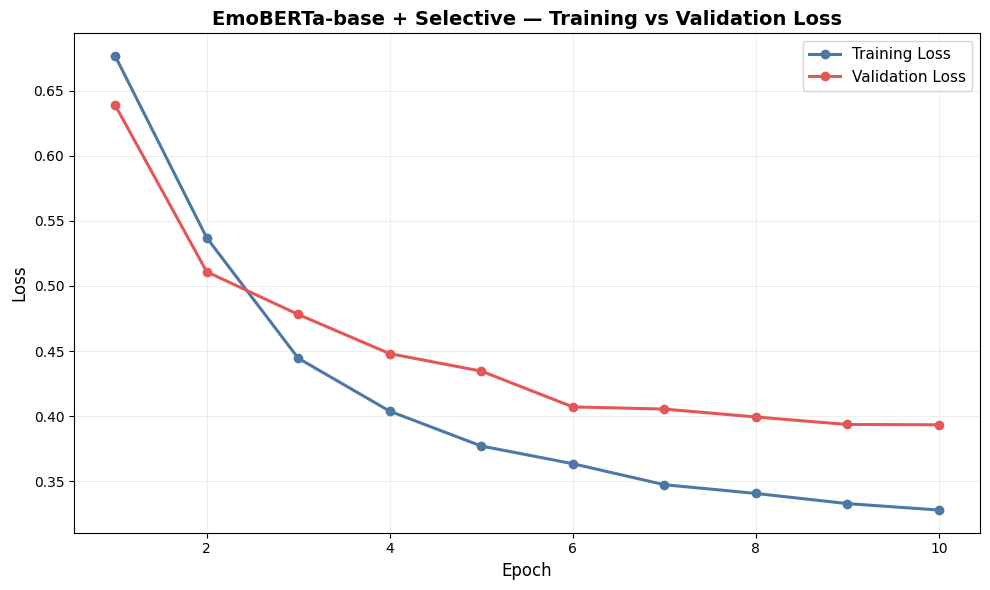

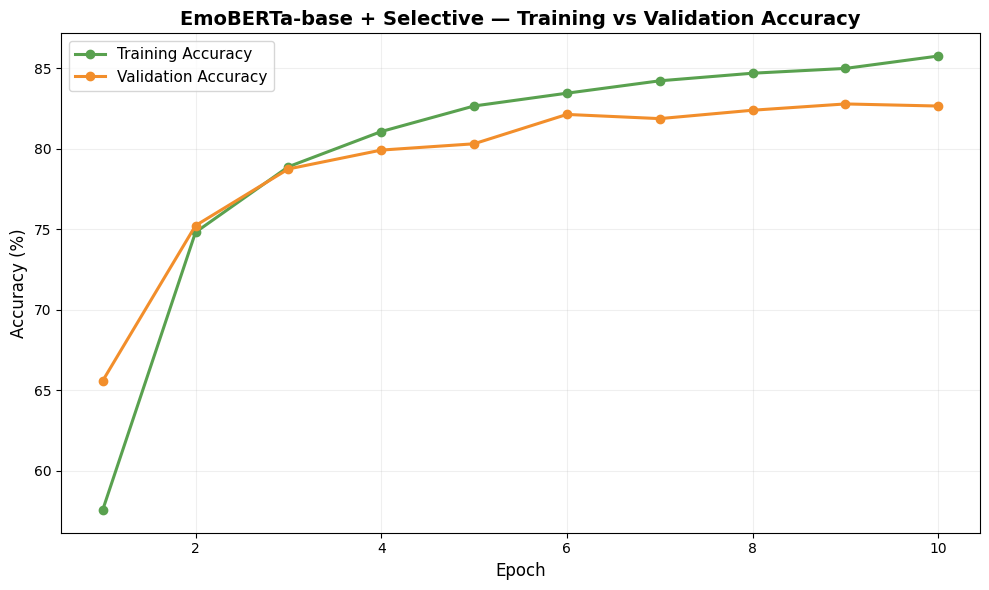

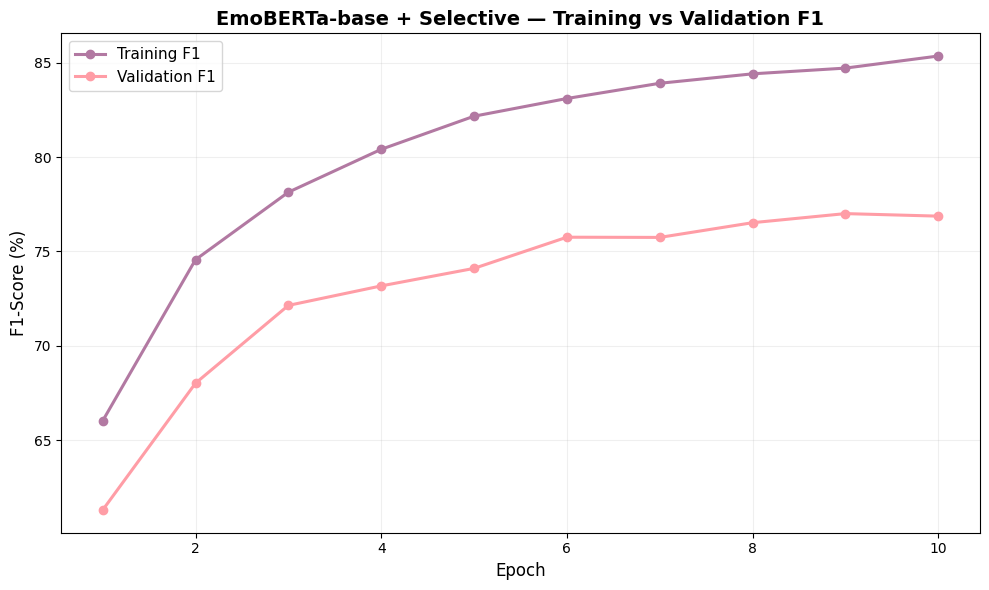

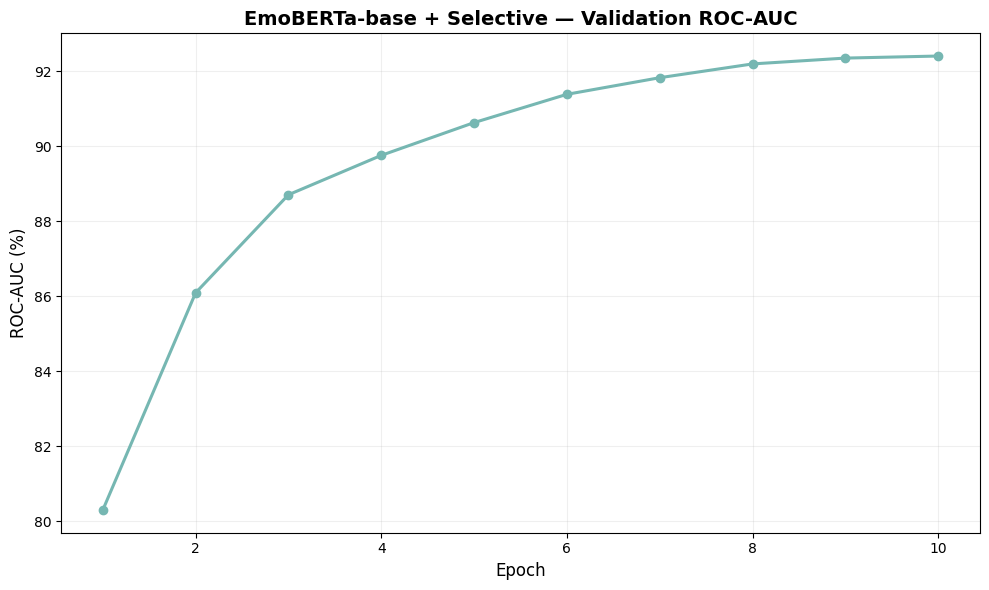

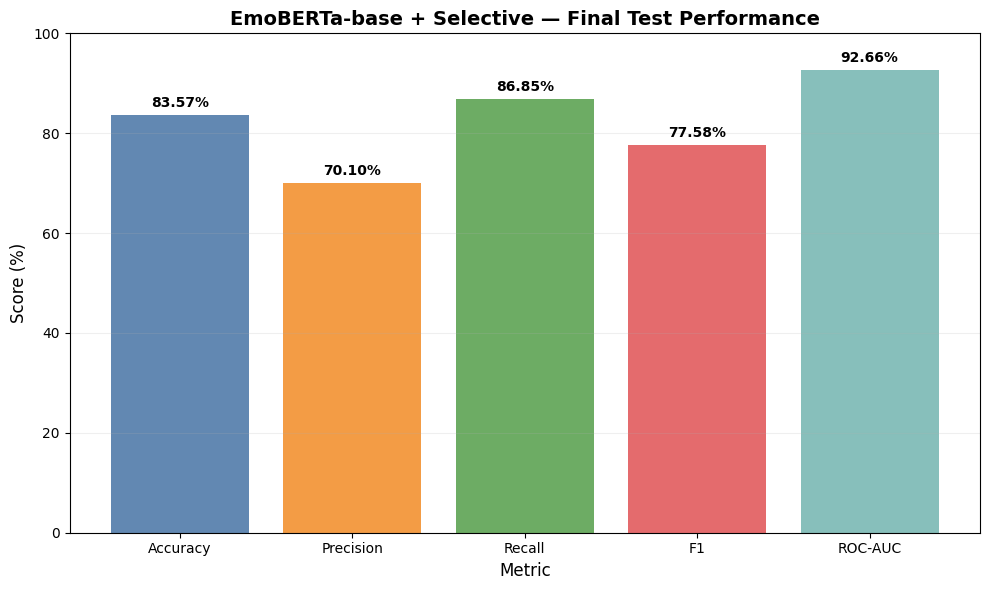

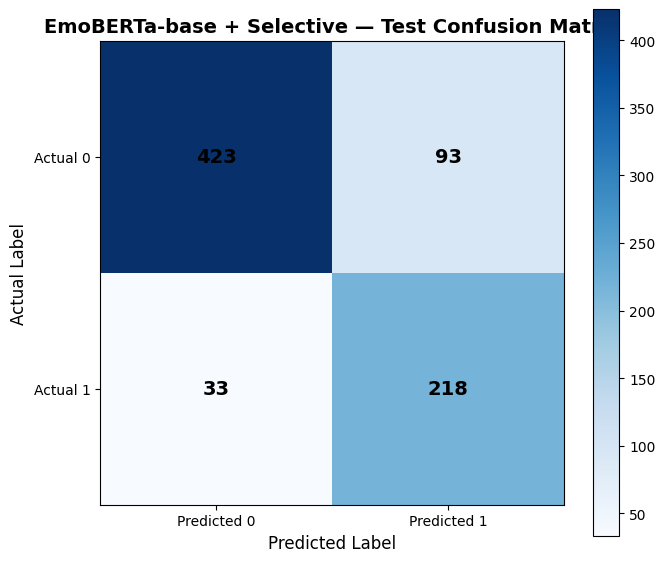


CELL 14 COMPLETE
✓ Final table printed
✓ Training Accuracy included
✓ Validation Accuracy included
✓ Testing Accuracy included
✓ Precision included
✓ Recall included
✓ F1 included
✓ ROC-AUC included
✓ Loss graph saved and displayed
✓ Accuracy graph saved and displayed
✓ F1 graph saved and displayed
✓ Validation ROC-AUC graph saved and displayed
✓ Final test metrics graph saved and displayed
✓ Confusion matrix saved and displayed

Graphs: /kaggle/working/emoberta_selective/graphs
Tables: /kaggle/working/emoberta_selective/tables


In [16]:
# ============================================================
# CELL 14 — EMOBERTA-BASE + SELECTIVE
# FINAL RESULTS TABLE + GRAPHS
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("EMOBERTA-BASE + SELECTIVE — GRAPHS + TABLES")
print("=" * 70)

# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

GRAPH_DIR = os.path.join(
    BASE_RESULT_DIR,
    "graphs"
)

TABLE_DIR = os.path.join(
    BASE_RESULT_DIR,
    "tables"
)

os.makedirs(
    GRAPH_DIR,
    exist_ok=True
)

os.makedirs(
    TABLE_DIR,
    exist_ok=True
)


# ============================================================
# LOAD FINAL TEST RESULTS
# ============================================================

with open(
    os.path.join(
        RESULT_DIR,
        "emoberta_selective_test_metrics.json"
    ),
    "r"
) as f:

    final_metrics = json.load(f)


# ============================================================
# LOAD TRAINING HISTORY
# ============================================================

history_df = pd.read_csv(
    os.path.join(
        RESULT_DIR,
        "emoberta_selective_training_history.csv"
    )
)


# ============================================================
# BEST EPOCH
# ============================================================

best_epoch = int(
    final_metrics[
        "best_epoch"
    ]
)

best_epoch_row = (
    history_df[
        history_df["epoch"] == best_epoch
    ]
    .iloc[0]
)


# ============================================================
# FINAL RESULTS TABLE
# ============================================================

results_table = pd.DataFrame({

    "Cleaning / Experiment":
        ["EmoBERTa-base + Selective"],

    "Training Accuracy":
        [
            best_epoch_row[
                "train_accuracy"
            ] * 100
        ],

    "Validation Accuracy":
        [
            best_epoch_row[
                "val_accuracy"
            ] * 100
        ],

    "Testing Accuracy":
        [
            final_metrics[
                "accuracy"
            ] * 100
        ],

    "Precision":
        [
            final_metrics[
                "precision"
            ] * 100
        ],

    "Recall":
        [
            final_metrics[
                "recall"
            ] * 100
        ],

    "F1":
        [
            final_metrics[
                "f1"
            ] * 100
        ],

    "ROC-AUC":
        [
            final_metrics[
                "roc_auc"
            ] * 100
        ]

}).round(2)


# ============================================================
# PRINT FINAL TABLE
# ============================================================

print()
print("=" * 100)
print("FINAL RESULTS TABLE")
print("=" * 100)

print(
    results_table.to_string(
        index=False
    )
)


# ============================================================
# SAVE FINAL TABLE
# ============================================================

results_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "emoberta_selective_final_results.csv"
    ),
    index=False
)


# ============================================================
# SAVE TRAINING HISTORY TABLE
# ============================================================

history_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "emoberta_selective_training_history.csv"
    ),
    index=False
)


# ============================================================
# GRAPH 1 — TRAINING VS VALIDATION LOSS
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    linewidth=2.2,
    color="#4C78A8",
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    linewidth=2.2,
    color="#E45756",
    label="Validation Loss"
)

plt.xlabel(
    "Epoch",
    fontsize=12
)

plt.ylabel(
    "Loss",
    fontsize=12
)

plt.title(
    "EmoBERTa-base + Selective — Training vs Validation Loss",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    fontsize=11
)

plt.grid(
    alpha=0.20
)

plt.tight_layout()

loss_path = os.path.join(
    GRAPH_DIR,
    "emoberta_selective_loss_curve.png"
)

plt.savefig(
    loss_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# GRAPH 2 — TRAINING VS VALIDATION ACCURACY
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"] * 100,
    marker="o",
    linewidth=2.2,
    color="#59A14F",
    label="Training Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"] * 100,
    marker="o",
    linewidth=2.2,
    color="#F28E2B",
    label="Validation Accuracy"
)

plt.xlabel(
    "Epoch",
    fontsize=12
)

plt.ylabel(
    "Accuracy (%)",
    fontsize=12
)

plt.title(
    "EmoBERTa-base + Selective — Training vs Validation Accuracy",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    fontsize=11
)

plt.grid(
    alpha=0.20
)

plt.tight_layout()

accuracy_path = os.path.join(
    GRAPH_DIR,
    "emoberta_selective_accuracy_curve.png"
)

plt.savefig(
    accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# GRAPH 3 — TRAINING VS VALIDATION F1
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["epoch"],
    history_df["train_f1"] * 100,
    marker="o",
    linewidth=2.2,
    color="#B279A2",
    label="Training F1"
)

plt.plot(
    history_df["epoch"],
    history_df["val_f1"] * 100,
    marker="o",
    linewidth=2.2,
    color="#FF9DA6",
    label="Validation F1"
)

plt.xlabel(
    "Epoch",
    fontsize=12
)

plt.ylabel(
    "F1-Score (%)",
    fontsize=12
)

plt.title(
    "EmoBERTa-base + Selective — Training vs Validation F1",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    fontsize=11
)

plt.grid(
    alpha=0.20
)

plt.tight_layout()

f1_path = os.path.join(
    GRAPH_DIR,
    "emoberta_selective_f1_curve.png"
)

plt.savefig(
    f1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# GRAPH 4 — VALIDATION ROC-AUC
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["epoch"],
    history_df["val_roc_auc"] * 100,
    marker="o",
    linewidth=2.2,
    color="#76B7B2"
)

plt.xlabel(
    "Epoch",
    fontsize=12
)

plt.ylabel(
    "ROC-AUC (%)",
    fontsize=12
)

plt.title(
    "EmoBERTa-base + Selective — Validation ROC-AUC",
    fontsize=14,
    fontweight="bold"
)

plt.grid(
    alpha=0.20
)

plt.tight_layout()

roc_path = os.path.join(
    GRAPH_DIR,
    "emoberta_selective_validation_roc_auc.png"
)

plt.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# GRAPH 5 — FINAL TEST METRICS
# ============================================================

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

metric_values = [
    final_metrics["accuracy"] * 100,
    final_metrics["precision"] * 100,
    final_metrics["recall"] * 100,
    final_metrics["f1"] * 100,
    final_metrics["roc_auc"] * 100
]

metric_colors = [
    "#4C78A8",
    "#F28E2B",
    "#59A14F",
    "#E15759",
    "#76B7B2"
]

plt.figure(
    figsize=(10, 6)
)

bars = plt.bar(
    metric_names,
    metric_values,
    color=metric_colors,
    alpha=0.88
)

plt.xlabel(
    "Metric",
    fontsize=12
)

plt.ylabel(
    "Score (%)",
    fontsize=12
)

plt.ylim(
    0,
    100
)

plt.title(
    "EmoBERTa-base + Selective — Final Test Performance",
    fontsize=14,
    fontweight="bold"
)

for bar, value in zip(
    bars,
    metric_values
):

    plt.text(
        bar.get_x()
        +
        bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.grid(
    axis="y",
    alpha=0.20
)

plt.tight_layout()

final_metrics_path = os.path.join(
    GRAPH_DIR,
    "emoberta_selective_final_metrics.png"
)

plt.savefig(
    final_metrics_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# GRAPH 6 — CONFUSION MATRIX
# ============================================================

cm = np.array(
    final_metrics[
        "confusion_matrix"
    ]
)

plt.figure(
    figsize=(7, 6)
)

plt.imshow(
    cm,
    cmap="Blues"
)

plt.colorbar()

plt.xticks(
    [0, 1],
    [
        "Predicted 0",
        "Predicted 1"
    ]
)

plt.yticks(
    [0, 1],
    [
        "Actual 0",
        "Actual 1"
    ]
)

plt.xlabel(
    "Predicted Label",
    fontsize=12
)

plt.ylabel(
    "Actual Label",
    fontsize=12
)

plt.title(
    "EmoBERTa-base + Selective — Test Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=14,
            fontweight="bold"
        )

plt.tight_layout()

cm_path = os.path.join(
    GRAPH_DIR,
    "emoberta_selective_confusion_matrix.png"
)

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# SAVE SUMMARY TXT
# ============================================================

summary_path = os.path.join(
    TABLE_DIR,
    "emoberta_selective_final_summary.txt"
)

with open(
    summary_path,
    "w"
) as f:

    f.write(
        "EMOBERTA-BASE + SELECTIVE — FINAL RESULTS\n"
    )

    f.write(
        "===========================================\n\n"
    )

    f.write(
        f"Training Accuracy: "
        f"{best_epoch_row['train_accuracy'] * 100:.2f}%\n"
    )

    f.write(
        f"Validation Accuracy: "
        f"{best_epoch_row['val_accuracy'] * 100:.2f}%\n"
    )

    f.write(
        f"Testing Accuracy: "
        f"{final_metrics['accuracy'] * 100:.2f}%\n"
    )

    f.write(
        f"Precision: "
        f"{final_metrics['precision'] * 100:.2f}%\n"
    )

    f.write(
        f"Recall: "
        f"{final_metrics['recall'] * 100:.2f}%\n"
    )

    f.write(
        f"F1: "
        f"{final_metrics['f1'] * 100:.2f}%\n"
    )

    f.write(
        f"ROC-AUC: "
        f"{final_metrics['roc_auc'] * 100:.2f}%\n"
    )

    f.write(
        f"\nBest Epoch: {best_epoch}\n"
    )

    f.write(
        f"Best Validation F1: "
        f"{best_val_f1 * 100:.2f}%\n"
    )

    f.write(
        "\nConfusion Matrix:\n"
    )

    f.write(
        f"TN = {cm[0,0]}\n"
    )

    f.write(
        f"FP = {cm[0,1]}\n"
    )

    f.write(
        f"FN = {cm[1,0]}\n"
    )

    f.write(
        f"TP = {cm[1,1]}\n"
    )


# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("CELL 14 COMPLETE")
print("=" * 70)

print(
    "✓ Final table printed"
)

print(
    "✓ Training Accuracy included"
)

print(
    "✓ Validation Accuracy included"
)

print(
    "✓ Testing Accuracy included"
)

print(
    "✓ Precision included"
)

print(
    "✓ Recall included"
)

print(
    "✓ F1 included"
)

print(
    "✓ ROC-AUC included"
)

print(
    "✓ Loss graph saved and displayed"
)

print(
    "✓ Accuracy graph saved and displayed"
)

print(
    "✓ F1 graph saved and displayed"
)

print(
    "✓ Validation ROC-AUC graph saved and displayed"
)

print(
    "✓ Final test metrics graph saved and displayed"
)

print(
    "✓ Confusion matrix saved and displayed"
)

print()
print(
    "Graphs:",
    GRAPH_DIR
)

print(
    "Tables:",
    TABLE_DIR
)

t-SNE REPRESENTATION ANALYSIS
EMOBERTA-BASE + SELECTIVE

✓ EmoBERTa model in evaluation mode

EXTRACTING FUSED REPRESENTATIONS
Processed batch 1/48
Processed batch 10/48
Processed batch 20/48
Processed batch 30/48
Processed batch 40/48
Processed batch 48/48

FUSED REPRESENTATION SUMMARY
Fused representation shape: (767, 832)
Test users: 767
Fused dimensions: 832
Negative users: 516
Positive users: 251
Metadata gate: 0.507237

PCA REDUCTION
Original dimensions: 832
PCA dimensions: 50
Variance retained: 87.26%

t-SNE REDUCTION
t-SNE output shape: (767, 2)


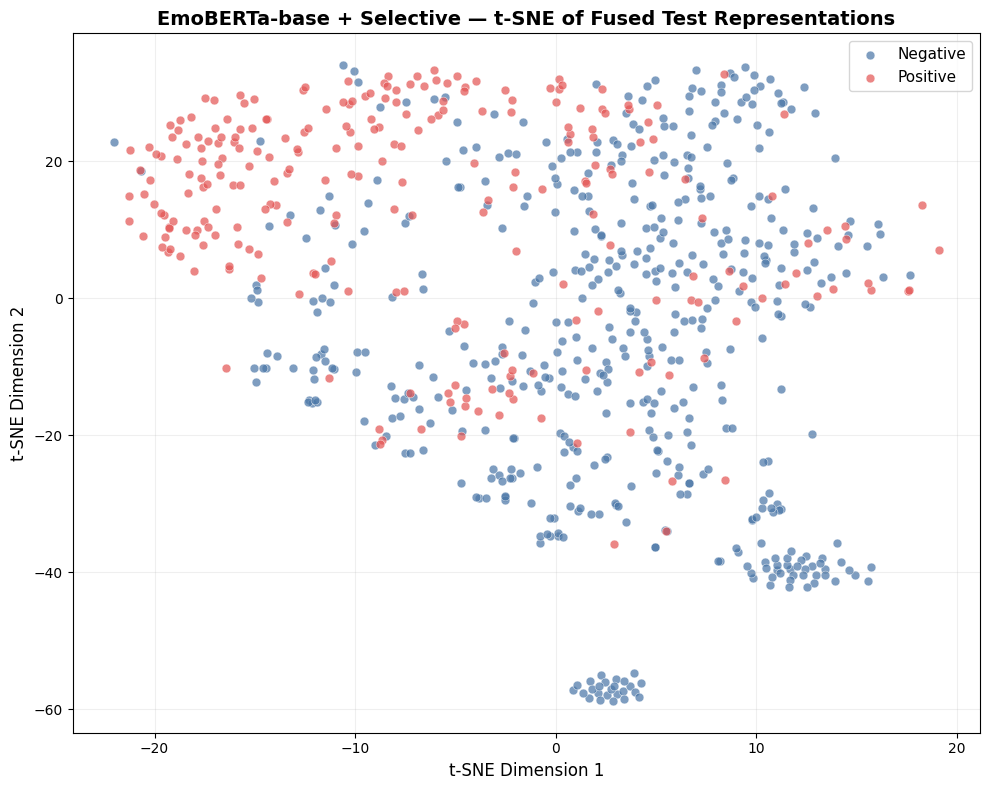


t-SNE ANALYSIS COMPLETE
✓ Exact EmoBERTa fused representation extracted
✓ PCA reduction completed
✓ t-SNE reduction completed
✓ t-SNE graph saved:
/kaggle/working/emoberta_selective/explainability/tsne/emoberta_selective_tsne.png
✓ t-SNE graph displayed above
✓ Coordinates saved:
/kaggle/working/emoberta_selective/explainability/tsne/emoberta_selective_tsne_coordinates.csv
✓ Configuration saved


In [17]:
# ============================================================
# CELL 15 — EMOBERTA-BASE + SELECTIVE
# t-SNE REPRESENTATION ANALYSIS
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

print("=" * 70)
print("t-SNE REPRESENTATION ANALYSIS")
print("EMOBERTA-BASE + SELECTIVE")
print("=" * 70)


# ============================================================
# FIXED EXPLAINABILITY SETTINGS
# ============================================================

EXPLAINABILITY_SEED = 42

PCA_COMPONENTS = 50

TSNE_COMPONENTS = 2
TSNE_PERPLEXITY = 30
TSNE_LEARNING_RATE = 200
TSNE_MAX_ITER = 1000

np.random.seed(
    EXPLAINABILITY_SEED
)

torch.manual_seed(
    EXPLAINABILITY_SEED
)


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)

TSNE_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "tsne"
)

os.makedirs(
    TSNE_DIR,
    exist_ok=True
)


# ============================================================
# MODEL
# ============================================================

model.eval()

print()
print("✓ EmoBERTa model in evaluation mode")


# ============================================================
# EXTRACT EXACT FUSED REPRESENTATION
# ============================================================

fused_representations = []
test_labels = []

print()
print("=" * 70)
print("EXTRACTING FUSED REPRESENTATIONS")
print("=" * 70)

with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_loader,
        start=1
    ):

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        # ----------------------------------------------------
        # EMOBERTA ENCODER
        # ----------------------------------------------------

        encoder_output = model.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden_states = (
            encoder_output.last_hidden_state
        )


        # ----------------------------------------------------
        # EXACT TEXT ATTENTION POOLING
        # ----------------------------------------------------

        projected = torch.tanh(
            model.attention_projection(
                hidden_states
            )
        )

        attention_scores = (
            model.attention_score(
                projected
            )
            .squeeze(-1)
        )

        attention_scores = (
            attention_scores.masked_fill(
                attention_mask == 0,
                -1e9
            )
        )

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        text_representation = torch.sum(
            hidden_states
            *
            attention_weights.unsqueeze(-1),
            dim=1
        )


        # ----------------------------------------------------
        # EXACT METADATA BRANCH
        # ----------------------------------------------------

        metadata_representation = (
            model.metadata_branch(
                metadata
            )
        )


        # ----------------------------------------------------
        # EXACT LEARNED METADATA GATE
        # ----------------------------------------------------

        metadata_gate = torch.sigmoid(
            model.metadata_beta
        )

        gated_metadata = (
            metadata_gate
            *
            metadata_representation
        )


        # ----------------------------------------------------
        # EXACT FUSED REPRESENTATION
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        fused_representations.append(
            fused.cpu().numpy()
        )

        test_labels.extend(
            labels.cpu().numpy().tolist()
        )

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx == len(test_loader)
        ):

            print(
                f"Processed batch "
                f"{batch_idx}/{len(test_loader)}"
            )


# ============================================================
# COMBINE
# ============================================================

fused_representations = np.concatenate(
    fused_representations,
    axis=0
)

test_labels = np.array(
    test_labels
)


# ============================================================
# REPRESENTATION SUMMARY
# ============================================================

print()
print("=" * 70)
print("FUSED REPRESENTATION SUMMARY")
print("=" * 70)

print(
    "Fused representation shape:",
    fused_representations.shape
)

print(
    "Test users:",
    len(test_labels)
)

print(
    "Fused dimensions:",
    fused_representations.shape[1]
)

print(
    "Negative users:",
    int(
        (test_labels == 0).sum()
    )
)

print(
    "Positive users:",
    int(
        (test_labels == 1).sum()
    )
)

print(
    "Metadata gate:",
    f"{float(metadata_gate.item()):.6f}"
)

assert (
    fused_representations.shape[0]
    ==
    len(test_labels)
)

assert np.isfinite(
    fused_representations
).all()


# ============================================================
# PCA
# ============================================================

print()
print("=" * 70)
print("PCA REDUCTION")
print("=" * 70)

pca_dimensions = min(
    PCA_COMPONENTS,
    fused_representations.shape[1]
)

pca = PCA(
    n_components=pca_dimensions,
    random_state=EXPLAINABILITY_SEED
)

pca_representation = pca.fit_transform(
    fused_representations
)

pca_variance_retained = (
    pca.explained_variance_ratio_.sum()
)

print(
    "Original dimensions:",
    fused_representations.shape[1]
)

print(
    "PCA dimensions:",
    pca_representation.shape[1]
)

print(
    "Variance retained:",
    f"{pca_variance_retained * 100:.2f}%"
)


# ============================================================
# t-SNE
# ============================================================

print()
print("=" * 70)
print("t-SNE REDUCTION")
print("=" * 70)

tsne = TSNE(
    n_components=TSNE_COMPONENTS,
    perplexity=TSNE_PERPLEXITY,
    learning_rate=TSNE_LEARNING_RATE,
    init="pca",
    random_state=EXPLAINABILITY_SEED,
    max_iter=TSNE_MAX_ITER
)

tsne_representation = tsne.fit_transform(
    pca_representation
)

print(
    "t-SNE output shape:",
    tsne_representation.shape
)


# ============================================================
# SAVE COORDINATES
# ============================================================

tsne_df = pd.DataFrame({

    "tsne_1":
        tsne_representation[:, 0],

    "tsne_2":
        tsne_representation[:, 1],

    "label":
        test_labels

})

tsne_df["class"] = tsne_df[
    "label"
].map({
    0: "Negative",
    1: "Positive"
})

tsne_csv_path = os.path.join(
    TSNE_DIR,
    "emoberta_selective_tsne_coordinates.csv"
)

tsne_df.to_csv(
    tsne_csv_path,
    index=False
)


# ============================================================
# PUBLICATION-QUALITY t-SNE PLOT
# ============================================================

plt.figure(
    figsize=(10, 8)
)

negative_mask = (
    test_labels == 0
)

positive_mask = (
    test_labels == 1
)

plt.scatter(
    tsne_representation[
        negative_mask,
        0
    ],
    tsne_representation[
        negative_mask,
        1
    ],
    s=40,
    alpha=0.72,
    label="Negative",
    color="#4C78A8",
    edgecolors="white",
    linewidths=0.4
)

plt.scatter(
    tsne_representation[
        positive_mask,
        0
    ],
    tsne_representation[
        positive_mask,
        1
    ],
    s=40,
    alpha=0.72,
    label="Positive",
    color="#E45756",
    edgecolors="white",
    linewidths=0.4
)

plt.xlabel(
    "t-SNE Dimension 1",
    fontsize=12
)

plt.ylabel(
    "t-SNE Dimension 2",
    fontsize=12
)

plt.title(
    "EmoBERTa-base + Selective — "
    "t-SNE of Fused Test Representations",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    fontsize=11
)

plt.grid(
    alpha=0.20
)

plt.tight_layout()

tsne_plot_path = os.path.join(
    TSNE_DIR,
    "emoberta_selective_tsne.png"
)

# SAVE
plt.savefig(
    tsne_plot_path,
    dpi=300,
    bbox_inches="tight"
)

# DISPLAY
plt.show()

plt.close()


# ============================================================
# SAVE CONFIGURATION
# ============================================================

tsne_config = {

    "model":
        "EmoBERTa-base",

    "cleaning":
        "Selective",

    "dataset":
        "Held-out test set",

    "test_users":
        int(len(test_labels)),

    "input_representation":
        "Fused classifier representation",

    "text_representation_dimension":
        int(
            text_representation.shape[1]
        ),

    "metadata_representation_dimension":
        int(
            metadata_representation.shape[1]
        ),

    "fused_representation_dimension":
        int(
            fused_representations.shape[1]
        ),

    "pca_dimensions":
        int(
            pca_dimensions
        ),

    "pca_variance_retained":
        float(
            pca_variance_retained
        ),

    "tsne_dimensions":
        int(
            TSNE_COMPONENTS
        ),

    "tsne_perplexity":
        int(
            TSNE_PERPLEXITY
        ),

    "tsne_learning_rate":
        TSNE_LEARNING_RATE,

    "tsne_max_iterations":
        int(
            TSNE_MAX_ITER
        ),

    "random_seed":
        EXPLAINABILITY_SEED,

    "metadata_gate":
        float(
            metadata_gate.item()
        )

}

with open(
    os.path.join(
        TSNE_DIR,
        "emoberta_selective_tsne_config.json"
    ),
    "w"
) as f:

    json.dump(
        tsne_config,
        f,
        indent=2
    )


# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("t-SNE ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ Exact EmoBERTa fused representation extracted"
)

print(
    "✓ PCA reduction completed"
)

print(
    "✓ t-SNE reduction completed"
)

print(
    "✓ t-SNE graph saved:"
)

print(
    tsne_plot_path
)

print(
    "✓ t-SNE graph displayed above"
)

print(
    "✓ Coordinates saved:"
)

print(
    tsne_csv_path
)

print(
    "✓ Configuration saved"
)

SHAP ANALYSIS
EMOBERTA-BASE + SELECTIVE

Total metadata features: 53

SHAP background samples: 50
Background dimensions: 53

SHAP test samples: 100
Negative: 50
Positive: 50

✓ EmoBERTa Selective model set to evaluation mode
✓ Model parameters frozen for SHAP

COMPUTING SHAP VALUES
Explained 1/100 test users
Explained 10/100 test users
Explained 20/100 test users
Explained 30/100 test users
Explained 40/100 test users
Explained 50/100 test users
Explained 60/100 test users
Explained 70/100 test users
Explained 80/100 test users
Explained 90/100 test users
Explained 100/100 test users

SHAP RESULT SUMMARY
SHAP matrix: (100, 53)
Metadata matrix: (100, 53)

TOP 20 SHAP FEATURES
                 feature  mean_abs_shap  mean_signed_shap
             tweet_count       0.026314          0.004943
             lda_topic_2       0.023056          0.011795
             lda_topic_9       0.018653          0.005026
              word_count       0.016997          0.003679
            lda_topic_13  

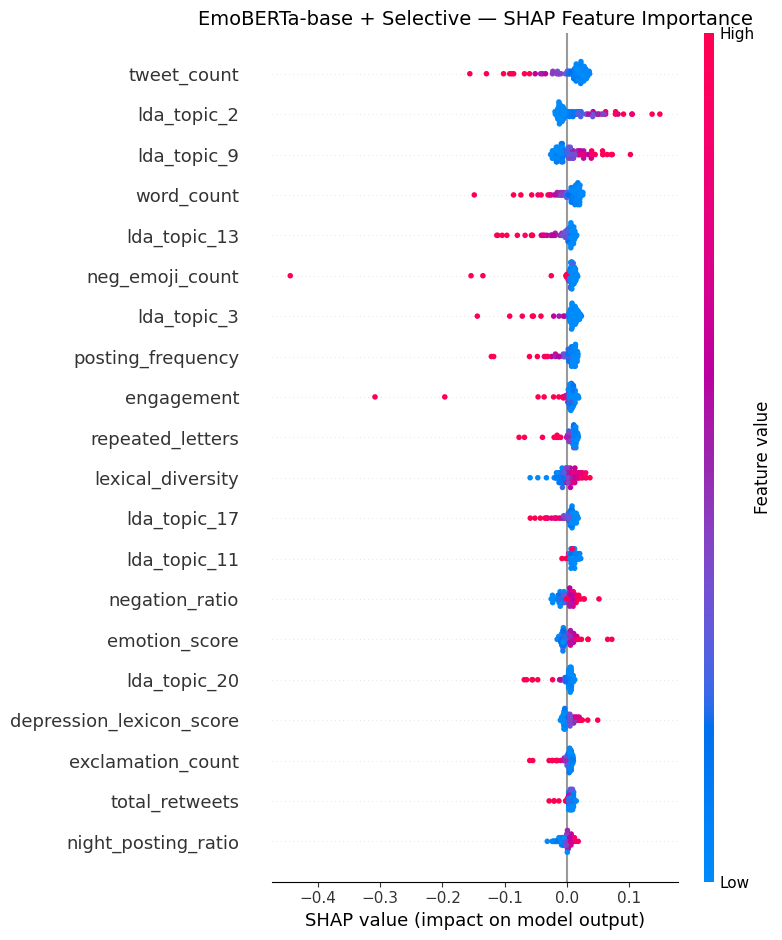

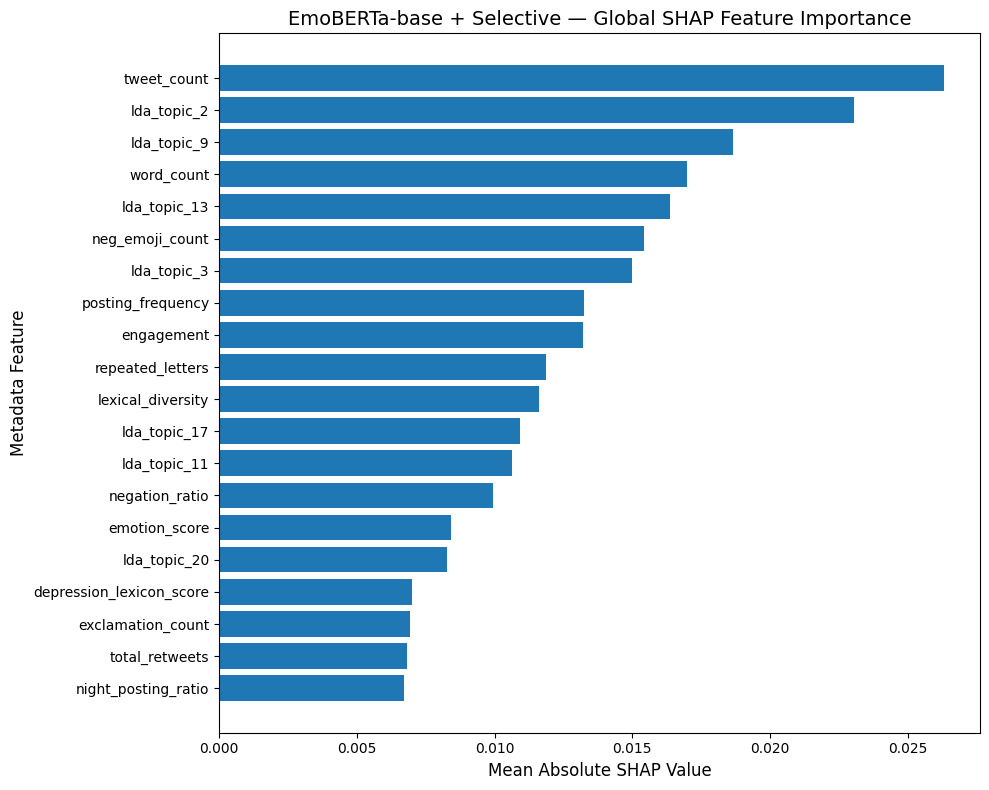


SHAP ANALYSIS COMPLETE
✓ 53 metadata features explained
✓ 50 negative + 50 positive users
✓ Training-only background used
✓ Positive-class logit explained
✓ SHAP values saved
✓ Feature ranking saved
✓ Beeswarm saved and displayed
✓ Bar plot saved and displayed
✓ Configuration saved

SHAP output directory: /kaggle/working/emoberta_selective/explainability/shap


In [18]:
# ============================================================
# EXPLAINABILITY — SHAP
# EMOBERTA-BASE + SELECTIVE
# GLOBAL METADATA FEATURE EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap

print("=" * 70)
print("SHAP ANALYSIS")
print("EMOBERTA-BASE + SELECTIVE")
print("=" * 70)


# ============================================================
# FIXED SHAP SETTINGS
# ============================================================

SHAP_SEED = 42
SHAP_BACKGROUND_SIZE = 50
SHAP_TEST_SIZE_PER_CLASS = 50
SHAP_TOP_FEATURES = 20

np.random.seed(SHAP_SEED)
torch.manual_seed(SHAP_SEED)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

SHAP_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "shap"
)

os.makedirs(
    SHAP_DIR,
    exist_ok=True
)


# ============================================================
# FEATURE NAMES
# ============================================================

feature_names = list(
    selected_metadata_names
)

assert len(feature_names) == 53

print()
print(
    "Total metadata features:",
    len(feature_names)
)


# ============================================================
# FIXED BACKGROUND DATA
# TRAINING USERS ONLY
# ============================================================

background_metadata = (
    train_dataset.metadata[
        :SHAP_BACKGROUND_SIZE
    ]
    .clone()
    .detach()
    .to(device)
)

print()
print(
    "SHAP background samples:",
    background_metadata.shape[0]
)

print(
    "Background dimensions:",
    background_metadata.shape[1]
)

assert background_metadata.shape[1] == 53


# ============================================================
# FIXED TEST USERS
# 50 NEGATIVE + 50 POSITIVE
# ============================================================

test_labels_tensor = (
    test_dataset.labels
    .detach()
    .cpu()
)

negative_indices = torch.where(
    test_labels_tensor == 0
)[0].numpy()

positive_indices = torch.where(
    test_labels_tensor == 1
)[0].numpy()

assert len(
    negative_indices
) >= SHAP_TEST_SIZE_PER_CLASS

assert len(
    positive_indices
) >= SHAP_TEST_SIZE_PER_CLASS


shap_negative_indices = (
    negative_indices[
        :SHAP_TEST_SIZE_PER_CLASS
    ]
)

shap_positive_indices = (
    positive_indices[
        :SHAP_TEST_SIZE_PER_CLASS
    ]
)

shap_test_indices = np.concatenate(
    [
        shap_negative_indices,
        shap_positive_indices
    ]
)

print()
print(
    "SHAP test samples:",
    len(shap_test_indices)
)

print(
    "Negative:",
    len(shap_negative_indices)
)

print(
    "Positive:",
    len(shap_positive_indices)
)


# ============================================================
# MODEL WRAPPER
# ============================================================
# Explains metadata while keeping each user's
# Transformer text representation fixed.
# No model parameters are changed.

class MetadataSHAPWrapper(
    nn.Module
):

    def __init__(
        self,
        base_model,
        fixed_input_ids,
        fixed_attention_mask
    ):

        super().__init__()

        self.base_model = base_model

        self.fixed_input_ids = (
            fixed_input_ids.to(device)
        )

        self.fixed_attention_mask = (
            fixed_attention_mask.to(device)
        )


    def forward(
        self,
        metadata
    ):

        batch_size = metadata.size(0)

        input_ids = (
            self.fixed_input_ids
            .expand(
                batch_size,
                -1
            )
        )

        attention_mask = (
            self.fixed_attention_mask
            .expand(
                batch_size,
                -1
            )
        )

        output = self.base_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        # Positive/depression class logit
        positive_logit = output[
            "logits"
        ][:, 1:2]

        return positive_logit


# ============================================================
# MODEL PREPARATION
# USE THE NOTEBOOK'S EXISTING VARIABLE: model
# ============================================================

model.eval()

for parameter in model.parameters():
    parameter.requires_grad = False

print()
print("✓ EmoBERTa Selective model set to evaluation mode")
print("✓ Model parameters frozen for SHAP")


# ============================================================
# COMPUTE SHAP VALUES
# ============================================================

all_shap_values = []
all_metadata_values = []
all_explained_labels = []

print()
print("=" * 70)
print("COMPUTING SHAP VALUES")
print("=" * 70)


for count, test_index in enumerate(
    shap_test_indices,
    start=1
):

    sample = test_dataset[
        int(test_index)
    ]

    input_ids = (
        sample["input_ids"]
        .unsqueeze(0)
    )

    attention_mask = (
        sample["attention_mask"]
        .unsqueeze(0)
    )

    metadata_sample = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
    )

    label = int(
        sample["labels"].item()
    )


    # --------------------------------------------------------
    # USER-SPECIFIC SHAP WRAPPER
    # --------------------------------------------------------

    wrapper = MetadataSHAPWrapper(
        model,
        input_ids,
        attention_mask
    ).to(device)

    wrapper.eval()


    # --------------------------------------------------------
    # GRADIENT SHAP
    # --------------------------------------------------------

    explainer = shap.GradientExplainer(
        wrapper,
        background_metadata
    )

    shap_result = explainer.shap_values(
        metadata_sample
    )


    # --------------------------------------------------------
    # HANDLE SHAP OUTPUT FORMAT
    # --------------------------------------------------------

    if isinstance(
        shap_result,
        list
    ):

        shap_array = np.asarray(
            shap_result[0]
        )

    else:

        shap_array = np.asarray(
            shap_result
        )

    shap_array = np.squeeze(
        shap_array
    )

    assert shap_array.shape == (
        53,
    )


    all_shap_values.append(
        shap_array
    )

    all_metadata_values.append(
        metadata_sample
        .detach()
        .cpu()
        .numpy()
        .squeeze(0)
    )

    all_explained_labels.append(
        label
    )


    if (
        count == 1
        or count % 10 == 0
        or count == len(
            shap_test_indices
        )
    ):

        print(
            f"Explained "
            f"{count}/"
            f"{len(shap_test_indices)} "
            f"test users"
        )


# ============================================================
# COMBINE RESULTS
# ============================================================

all_shap_values = np.vstack(
    all_shap_values
)

all_metadata_values = np.vstack(
    all_metadata_values
)

all_explained_labels = np.array(
    all_explained_labels
)

print()
print("=" * 70)
print("SHAP RESULT SUMMARY")
print("=" * 70)

print(
    "SHAP matrix:",
    all_shap_values.shape
)

print(
    "Metadata matrix:",
    all_metadata_values.shape
)

assert all_shap_values.shape == (
    len(shap_test_indices),
    53
)

assert all_metadata_values.shape == (
    len(shap_test_indices),
    53
)

assert np.isfinite(
    all_shap_values
).all()


# ============================================================
# GLOBAL FEATURE IMPORTANCE
# ============================================================

mean_abs_shap = np.mean(
    np.abs(
        all_shap_values
    ),
    axis=0
)

mean_signed_shap = np.mean(
    all_shap_values,
    axis=0
)

feature_importance_df = pd.DataFrame({

    "feature":
        feature_names,

    "mean_abs_shap":
        mean_abs_shap,

    "mean_signed_shap":
        mean_signed_shap

})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

print()
print("=" * 70)
print("TOP 20 SHAP FEATURES")
print("=" * 70)

print(
    feature_importance_df
    .head(SHAP_TOP_FEATURES)
    .to_string(
        index=False
    )
)


# ============================================================
# SAVE SHAP VALUES
# ============================================================

shap_values_df = pd.DataFrame(
    all_shap_values,
    columns=feature_names
)

shap_values_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "emoberta_selective_shap_values.csv"
    ),
    index=False
)


# ============================================================
# SAVE FEATURE IMPORTANCE
# ============================================================

feature_importance_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "emoberta_selective_shap_feature_importance.csv"
    ),
    index=False
)


# ============================================================
# SAVE TEST USER INFORMATION
# ============================================================

explained_users_df = pd.DataFrame({

    "test_index":
        shap_test_indices,

    "label":
        all_explained_labels

})

explained_users_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "emoberta_selective_shap_test_users.csv"
    ),
    index=False
)


# ============================================================
# SHAP BEESWARM
# ============================================================

plt.figure(
    figsize=(11, 8)
)

shap.summary_plot(
    all_shap_values,
    all_metadata_values,
    feature_names=feature_names,
    max_display=SHAP_TOP_FEATURES,
    show=False
)

plt.title(
    "EmoBERTa-base + Selective — SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

shap_beeswarm_path = os.path.join(
    SHAP_DIR,
    "emoberta_selective_shap_beeswarm.png"
)

plt.savefig(
    shap_beeswarm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# SHAP BAR
# ============================================================

top_features = (
    feature_importance_df
    .head(
        SHAP_TOP_FEATURES
    )
    .iloc[::-1]
)

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    top_features["feature"],
    top_features["mean_abs_shap"]
)

plt.xlabel(
    "Mean Absolute SHAP Value",
    fontsize=12
)

plt.ylabel(
    "Metadata Feature",
    fontsize=12
)

plt.title(
    "EmoBERTa-base + Selective — Global SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

shap_bar_path = os.path.join(
    SHAP_DIR,
    "emoberta_selective_shap_bar.png"
)

plt.savefig(
    shap_bar_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# SAVE CONFIG
# ============================================================

shap_config = {

    "model":
        "EmoBERTa-base",

    "cleaning":
        "Selective",

    "dataset":
        "Held-out test set",

    "metadata_features":
        53,

    "background_samples":
        SHAP_BACKGROUND_SIZE,

    "test_samples_per_class":
        SHAP_TEST_SIZE_PER_CLASS,

    "total_explained_users":
        len(shap_test_indices),

    "target":
        "Positive/depression class logit",

    "explainer":
        "GradientExplainer",

    "text_fixed_per_user":
        True,

    "random_seed":
        SHAP_SEED,

    "top_features":
        SHAP_TOP_FEATURES
}

with open(
    os.path.join(
        SHAP_DIR,
        "emoberta_selective_shap_config.json"
    ),
    "w"
) as f:

    json.dump(
        shap_config,
        f,
        indent=2
    )


# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("SHAP ANALYSIS COMPLETE")
print("=" * 70)

print("✓ 53 metadata features explained")
print("✓ 50 negative + 50 positive users")
print("✓ Training-only background used")
print("✓ Positive-class logit explained")
print("✓ SHAP values saved")
print("✓ Feature ranking saved")
print("✓ Beeswarm saved and displayed")
print("✓ Bar plot saved and displayed")
print("✓ Configuration saved")

print()
print(
    "SHAP output directory:",
    SHAP_DIR
)

GRAD-CAM ANALYSIS
EMOBERTA-BASE + SELECTIVE

✓ EmoBERTa Selective model ready

Test users: 767

SELECTED CASES
TP: Test Index = 1 | True = 1 | Pred = 1 | Positive Probability = 0.8040
TN: Test Index = 0 | True = 0 | Pred = 0 | Positive Probability = 0.3188
FP: Test Index = 2 | True = 0 | Pred = 1 | Positive Probability = 0.5529
FN: Test Index = 14 | True = 1 | Pred = 0 | Positive Probability = 0.3036

COMPUTING GRAD-CAM

Processing TP (Test Index 1)
✓ TP complete

Processing TN (Test Index 0)
✓ TN complete

Processing FP (Test Index 2)
✓ FP complete

Processing FN (Test Index 14)
✓ FN complete


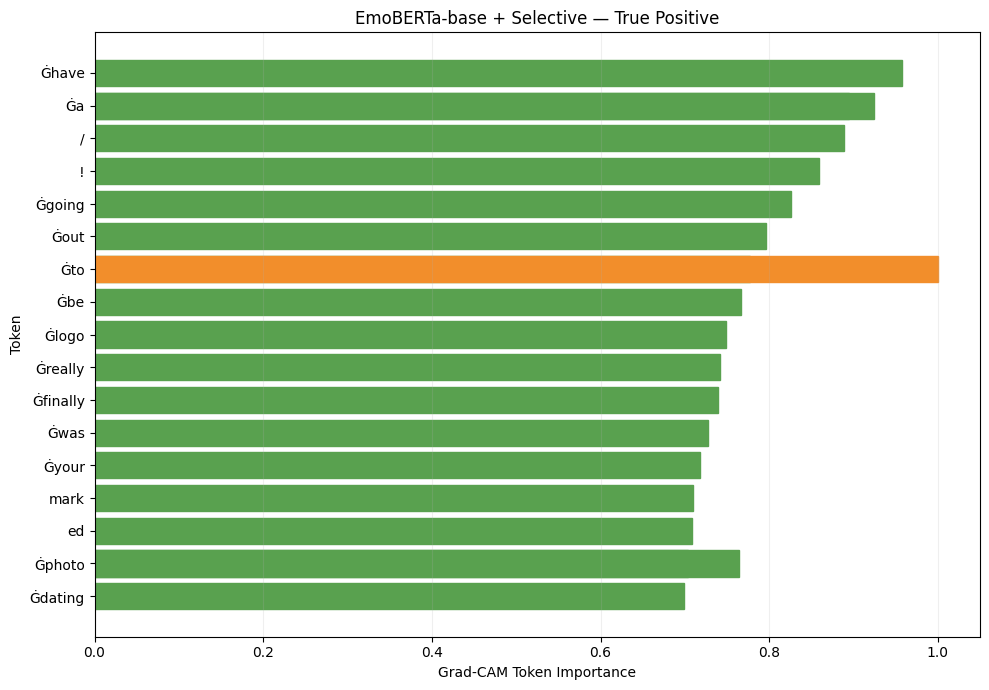

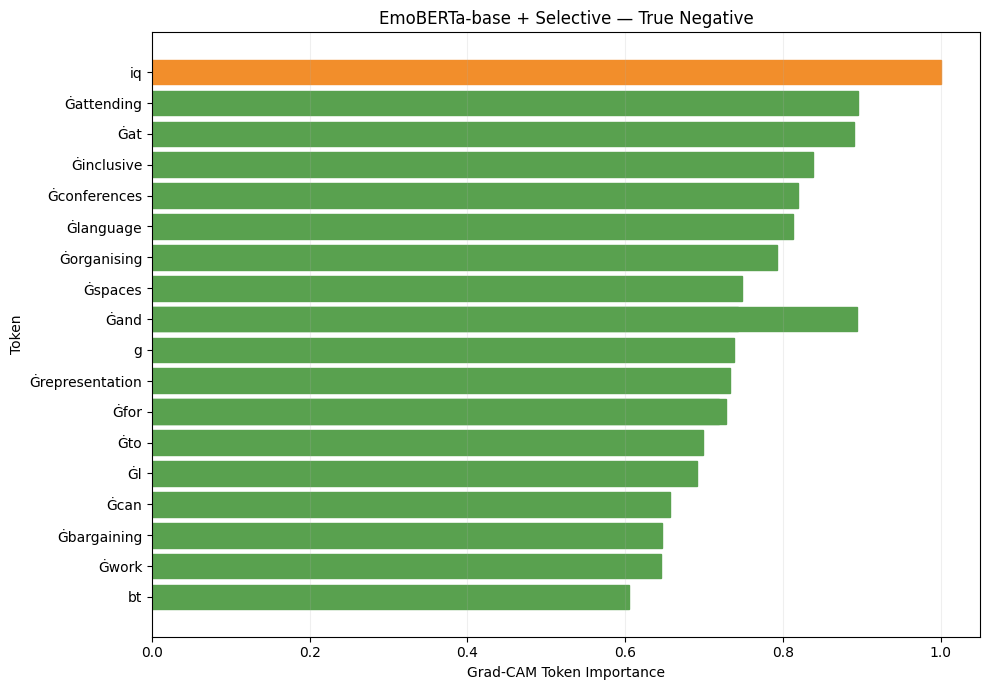

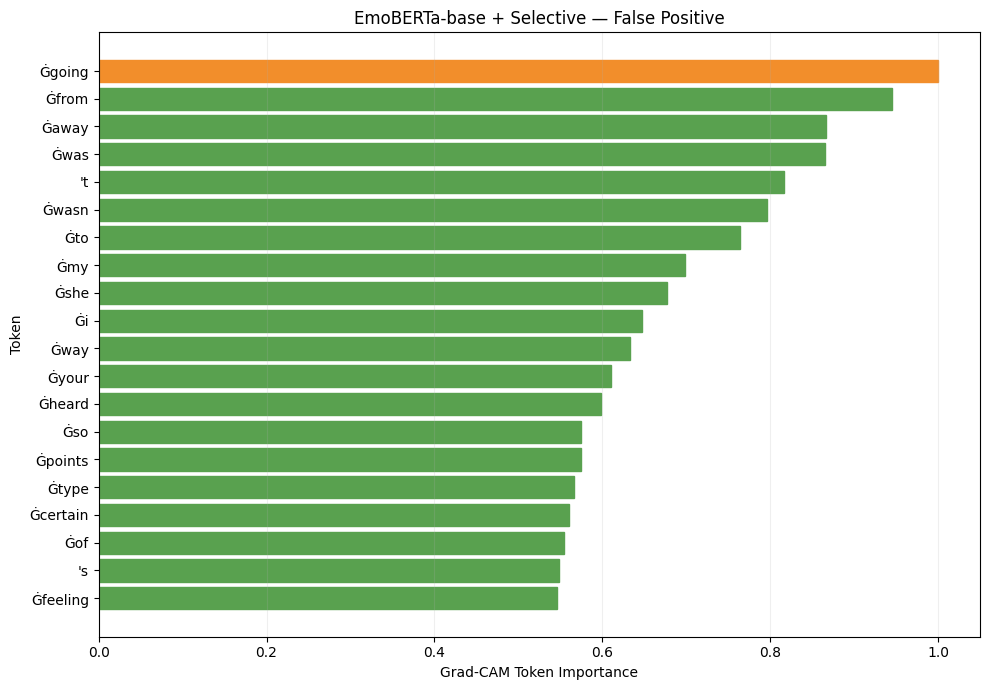

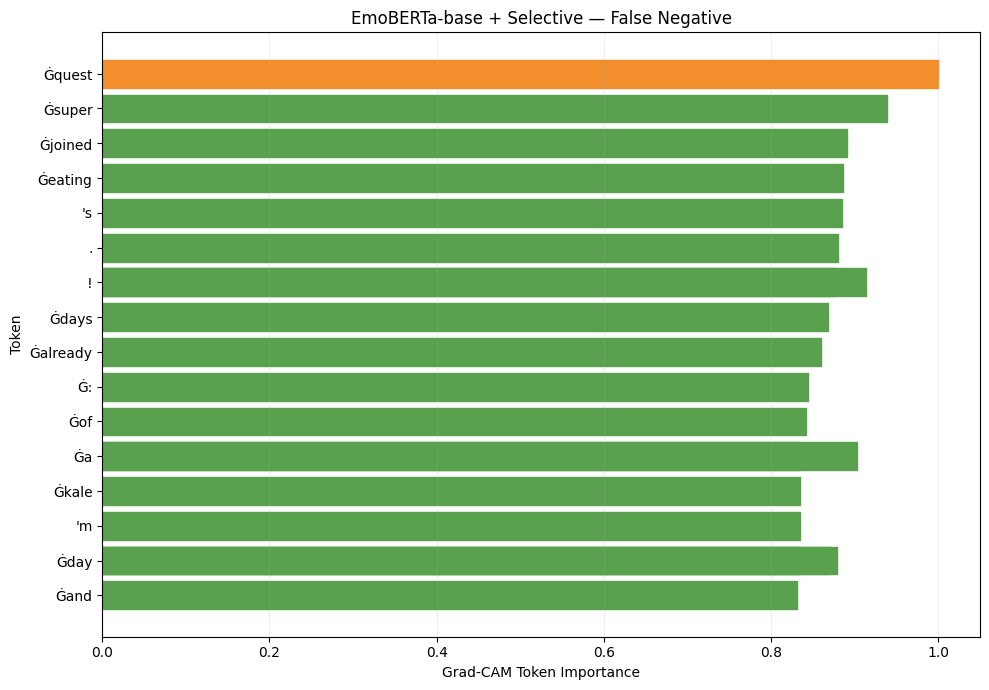


GRAD-CAM ANALYSIS COMPLETE

TP — True: 1 | Predicted: 1 | P(Positive): 0.8040
Top tokens: [('Ġto', 1.0), ('Ġhave', 0.9571433067321777), ('Ġa', 0.9245524406433105), ('Ġa', 0.8948113322257996), ('/', 0.8884447813034058), ('!', 0.8589738011360168), ('Ġgoing', 0.8259193301200867), ('Ġout', 0.7967095375061035), ('Ġto', 0.7774778008460999), ('Ġbe', 0.7662416100502014), ('Ġphoto', 0.7640496492385864), ('Ġlogo', 0.7486299276351929), ('Ġreally', 0.7420545220375061), ('Ġfinally', 0.7396438717842102), ('Ġwas', 0.727111279964447), ('Ġyour', 0.7175789475440979), ('mark', 0.7099145650863647), ('ed', 0.7081331610679626), ('Ġphoto', 0.7035855054855347), ('Ġdating', 0.6986947655677795)]

TN — True: 0 | Predicted: 0 | P(Positive): 0.3188
Top tokens: [('iq', 1.0), ('Ġattending', 0.8956423401832581), ('Ġand', 0.8943318128585815), ('Ġat', 0.8908085227012634), ('Ġinclusive', 0.8382406830787659), ('Ġconferences', 0.8192824721336365), ('Ġlanguage', 0.8128747344017029), ('Ġorganising', 0.792040228843689), ('Ġ

In [19]:
# ============================================================
# EXPLAINABILITY — GRAD-CAM
# EMOBERTA-BASE + SELECTIVE
# TOKEN-LEVEL EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

print("=" * 70)
print("GRAD-CAM ANALYSIS")
print("EMOBERTA-BASE + SELECTIVE")
print("=" * 70)


# ============================================================
# FIXED SETTINGS
# ============================================================

GRADCAM_SEED = 42
TOP_TOKENS = 20

np.random.seed(GRADCAM_SEED)
torch.manual_seed(GRADCAM_SEED)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

GRADCAM_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "gradcam"
)

os.makedirs(
    GRADCAM_DIR,
    exist_ok=True
)


# ============================================================
# MODEL
# ============================================================

model.eval()

for parameter in model.parameters():
    parameter.requires_grad = False

print()
print("✓ EmoBERTa Selective model ready")


# ============================================================
# COLLECT TEST PREDICTIONS
# ============================================================

test_true = []
test_pred = []
test_prob = []

with torch.no_grad():

    for batch in test_loader:

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs["logits"]

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]

        predictions = (
            probabilities >= 0.5
        ).long()

        test_true.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_pred.extend(
            predictions.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_prob.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )


test_true = np.asarray(
    test_true
)

test_pred = np.asarray(
    test_pred
)

test_prob = np.asarray(
    test_prob
)

print()
print(
    "Test users:",
    len(test_true)
)


# ============================================================
# DETERMINISTIC TP / TN / FP / FN CASES
# ============================================================

tp_candidates = np.where(
    (test_true == 1) &
    (test_pred == 1)
)[0]

tn_candidates = np.where(
    (test_true == 0) &
    (test_pred == 0)
)[0]

fp_candidates = np.where(
    (test_true == 0) &
    (test_pred == 1)
)[0]

fn_candidates = np.where(
    (test_true == 1) &
    (test_pred == 0)
)[0]


assert len(tp_candidates) > 0
assert len(tn_candidates) > 0
assert len(fp_candidates) > 0
assert len(fn_candidates) > 0


selected_cases = {

    "TP":
        int(tp_candidates[0]),

    "TN":
        int(tn_candidates[0]),

    "FP":
        int(fp_candidates[0]),

    "FN":
        int(fn_candidates[0])
}


print()
print("=" * 70)
print("SELECTED CASES")
print("=" * 70)

for case_name, index in selected_cases.items():

    print(
        f"{case_name}: "
        f"Test Index = {index} | "
        f"True = {test_true[index]} | "
        f"Pred = {test_pred[index]} | "
        f"Positive Probability = {test_prob[index]:.4f}"
    )


# ============================================================
# GRAD-CAM FUNCTION
# ============================================================

def compute_gradcam(
    sample_index
):

    sample = test_dataset[
        sample_index
    ]

    input_ids = (
        sample["input_ids"]
        .unsqueeze(0)
        .to(device)
    )

    attention_mask = (
        sample["attention_mask"]
        .unsqueeze(0)
        .to(device)
    )

    metadata = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
    )


    # --------------------------------------------------------
    # ENABLE GRADIENTS
    # --------------------------------------------------------

    model.zero_grad(
        set_to_none=True
    )


    # --------------------------------------------------------
    # EMOBERTA ENCODER
    # --------------------------------------------------------

    encoder_output = model.encoder(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

    hidden_states = (
        encoder_output.last_hidden_state
    )

    # Enable gradients on final hidden states
    # while keeping model weights frozen
    hidden_states.requires_grad_(True)
    hidden_states.retain_grad()


    # --------------------------------------------------------
    # ATTENTION POOLING
    # --------------------------------------------------------

    projected = torch.tanh(
        model.attention_projection(
            hidden_states
        )
    )

    attention_scores = (
        model.attention_score(
            projected
        )
        .squeeze(-1)
    )

    attention_scores = (
        attention_scores.masked_fill(
            attention_mask == 0,
            -1e9
        )
    )

    attention_weights = torch.softmax(
        attention_scores,
        dim=1
    )


    text_representation = torch.sum(
        hidden_states *
        attention_weights.unsqueeze(-1),
        dim=1
    )


    # --------------------------------------------------------
    # METADATA BRANCH
    # --------------------------------------------------------

    metadata_representation = (
        model.metadata_branch(
            metadata
        )
    )


    metadata_gate = torch.sigmoid(
        model.metadata_beta
    )

    gated_metadata = (
        metadata_gate *
        metadata_representation
    )


    # --------------------------------------------------------
    # FUSION
    # --------------------------------------------------------

    fused = torch.cat(
        [
            text_representation,
            gated_metadata
        ],
        dim=1
    )


    # --------------------------------------------------------
    # CLASSIFIER
    # --------------------------------------------------------

    logits = model.classifier(
        fused
    )

    positive_logit = (
        logits[:, 1]
    )

    positive_logit.backward()


    # --------------------------------------------------------
    # GRAD-CAM
    # --------------------------------------------------------

    gradients = hidden_states.grad

    channel_weights = gradients.mean(
        dim=1
    )

    cam = (
        (
            hidden_states *
            channel_weights.unsqueeze(1)
        )
        .sum(dim=2)
        .squeeze(0)
    )


    # ReLU
    cam = torch.relu(
        cam
    )


    # Normalize
    cam = (
        cam /
        (
            cam.max() +
            1e-12
        )
    )


    cam = (
        cam
        .detach()
        .cpu()
        .numpy()
    )

    tokens = tokenizer.convert_ids_to_tokens(
        input_ids.squeeze(0)
        .detach()
        .cpu()
        .tolist()
    )

    mask = (
        attention_mask.squeeze(0)
        .detach()
        .cpu()
        .numpy()
        .astype(bool)
    )


    tokens = [
        token
        for token, valid in zip(
            tokens,
            mask
        )
        if valid
    ]

    cam = cam[
        mask
    ]


    # --------------------------------------------------------
    # REMOVE SPECIAL TOKENS
    # --------------------------------------------------------

    valid_pairs = []

    special_tokens = {
        tokenizer.cls_token,
        tokenizer.sep_token,
        tokenizer.pad_token
    }

    for token, importance in zip(
        tokens,
        cam
    ):

        if token in special_tokens:
            continue

        valid_pairs.append(
            (
                token,
                float(importance)
            )
        )


    # --------------------------------------------------------
    # TOP TOKENS
    # --------------------------------------------------------

    valid_pairs = sorted(
        valid_pairs,
        key=lambda x: x[1],
        reverse=True
    )

    top_pairs = valid_pairs[
        :TOP_TOKENS
    ]

    return (
        top_pairs,
        tokens,
        cam,
        int(test_true[sample_index]),
        int(test_pred[sample_index]),
        float(test_prob[sample_index])
    )


# ============================================================
# RUN FOUR CASES
# ============================================================

gradcam_results = {}

print()
print("=" * 70)
print("COMPUTING GRAD-CAM")
print("=" * 70)


for case_name, sample_index in selected_cases.items():

    print()
    print(
        f"Processing {case_name} "
        f"(Test Index {sample_index})"
    )

    result = compute_gradcam(
        sample_index
    )

    gradcam_results[
        case_name
    ] = result

    print(
        f"✓ {case_name} complete"
    )


# ============================================================
# SAVE TOKEN IMPORTANCE CSV
# ============================================================

all_rows = []

for case_name, result in gradcam_results.items():

    top_pairs = result[0]

    true_label = result[3]
    predicted_label = result[4]
    positive_probability = result[5]

    for rank, (
        token,
        importance
    ) in enumerate(
        top_pairs,
        start=1
    ):

        all_rows.append({

            "case":
                case_name,

            "rank":
                rank,

            "token":
                token,

            "importance":
                importance,

            "true_label":
                true_label,

            "predicted_label":
                predicted_label,

            "positive_probability":
                positive_probability
        })


gradcam_df = pd.DataFrame(
    all_rows
)

gradcam_csv_path = os.path.join(
    GRADCAM_DIR,
    "emoberta_selective_gradcam_token_importance.csv"
)

gradcam_df.to_csv(
    gradcam_csv_path,
    index=False
)


# ============================================================
# PLOT FOUR CASES
# ============================================================

case_titles = {

    "TP":
        "True Positive",

    "TN":
        "True Negative",

    "FP":
        "False Positive",

    "FN":
        "False Negative"
}


for case_name, result in gradcam_results.items():

    top_pairs = result[0]

    tokens_plot = [
        pair[0]
        for pair in top_pairs
    ][::-1]

    importance_plot = [
        pair[1]
        for pair in top_pairs
    ][::-1]


    plt.figure(
        figsize=(10, 7)
    )

    bars = plt.barh(
        tokens_plot,
        importance_plot
    )


    # Highlight highest-importance token
    if len(bars) > 0:

        max_index = int(
            np.argmax(
                importance_plot
            )
        )

        bars[max_index].set_color(
            "#F28E2B"
        )

        for index, bar in enumerate(
            bars
        ):

            if index != max_index:

                bar.set_color(
                    "#59A14F"
                )


    plt.xlabel(
        "Grad-CAM Token Importance"
    )

    plt.ylabel(
        "Token"
    )

    plt.title(
        "EmoBERTa-base + Selective — "
        f"{case_titles[case_name]}"
    )

    plt.grid(
        axis="x",
        alpha=0.20
    )

    plt.tight_layout()


    plot_path = os.path.join(
        GRADCAM_DIR,
        f"emoberta_selective_gradcam_{case_name.lower()}.png"
    )

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ============================================================
# SAVE CONFIGURATION
# ============================================================

gradcam_config = {

    "model":
        "EmoBERTa-base",

    "cleaning":
        "Selective",

    "method":
        "Gradient-weighted Class Activation Mapping",

    "target":
        "Positive/depression-class logit",

    "representation":
        "Final Transformer hidden states",

    "channel_weight":
        "Mean gradient across token positions",

    "activation":
        "ReLU",

    "normalization":
        "Per-user max normalization",

    "top_tokens":
        TOP_TOKENS,

    "seed":
        GRADCAM_SEED,

    "cases":
        selected_cases,

    "test_users":
        len(test_true)

}


with open(
    os.path.join(
        GRADCAM_DIR,
        "emoberta_selective_gradcam_config.json"
    ),
    "w"
) as f:

    json.dump(
        gradcam_config,
        f,
        indent=2
    )


# ============================================================
# PRINT RESULTS
# ============================================================

print()
print("=" * 70)
print("GRAD-CAM ANALYSIS COMPLETE")
print("=" * 70)

for case_name, result in gradcam_results.items():

    print()
    print(
        f"{case_name} — "
        f"True: {result[3]} | "
        f"Predicted: {result[4]} | "
        f"P(Positive): {result[5]:.4f}"
    )

    print(
        "Top tokens:",
        result[0]
    )

print()
print(
    "✓ TP, TN, FP, FN cases explained"
)

print(
    "✓ Final EmoBERTa hidden states used"
)

print(
    "✓ Positive/depression-class logit used"
)

print(
    "✓ Top 20 tokens extracted"
)

print(
    "✓ Token importance CSV saved"
)

print(
    "✓ Four paper-ready plots saved and displayed"
)

print(
    "✓ Configuration saved"
)

print()
print(
    "Grad-CAM output directory:",
    GRADCAM_DIR
)

LIME ANALYSIS
EMOBERTA-BASE + SELECTIVE

✓ EmoBERTa Selective model ready

Test users: 767

SELECTED CASES
TP: Test Index = 1 | True = 1 | Pred = 1 | Positive Probability = 0.8040
TN: Test Index = 0 | True = 0 | Pred = 0 | Positive Probability = 0.3188
FP: Test Index = 2 | True = 0 | Pred = 1 | Positive Probability = 0.5529
FN: Test Index = 14 | True = 1 | Pred = 0 | Positive Probability = 0.3036

✓ LIME explainer ready

GENERATING LIME EXPLANATIONS

Processing TP (test index 1)...
✓ TP explanation complete

Processing TN (test index 0)...
✓ TN explanation complete

Processing FP (test index 2)...
✓ FP explanation complete

Processing FN (test index 14)...
✓ FN explanation complete

LIME EXPLANATIONS

TP — LIME LOCAL EXPLANATION



TN — LIME LOCAL EXPLANATION



FP — LIME LOCAL EXPLANATION



FN — LIME LOCAL EXPLANATION


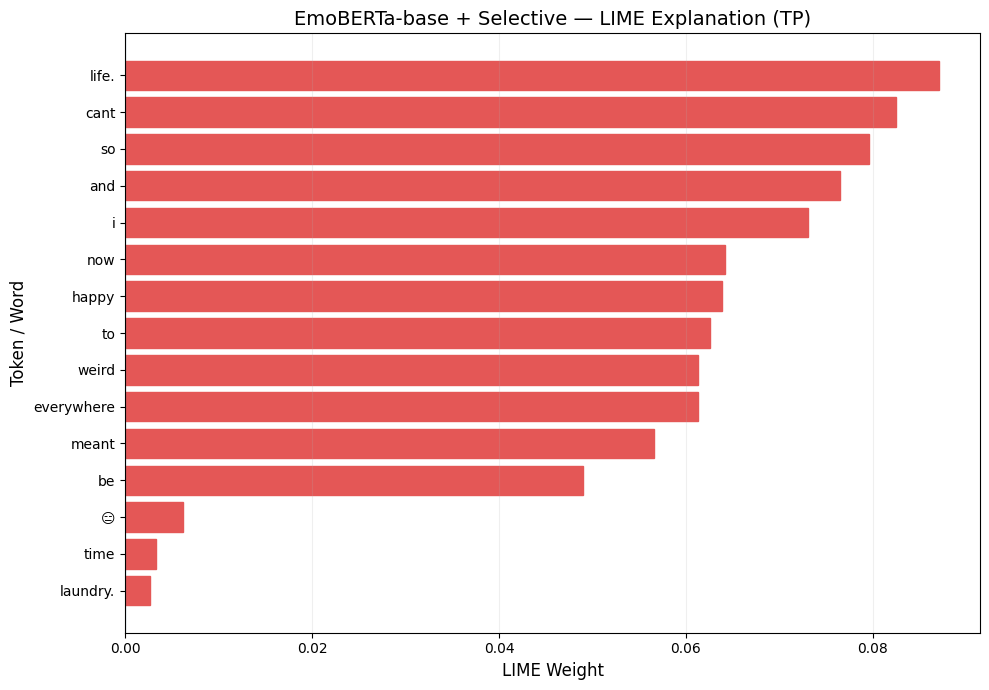

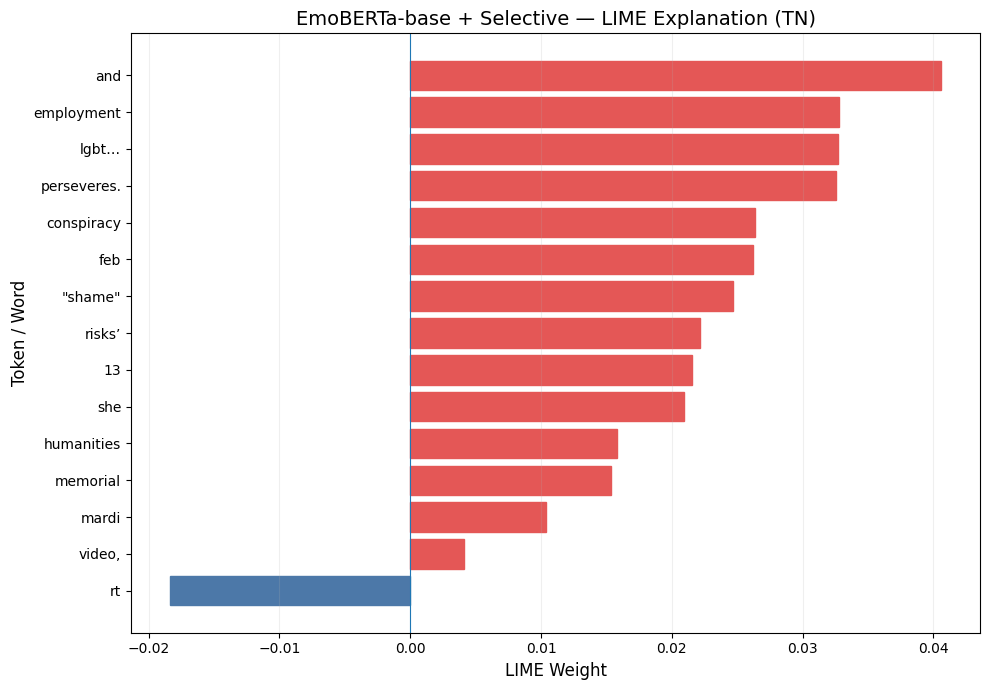

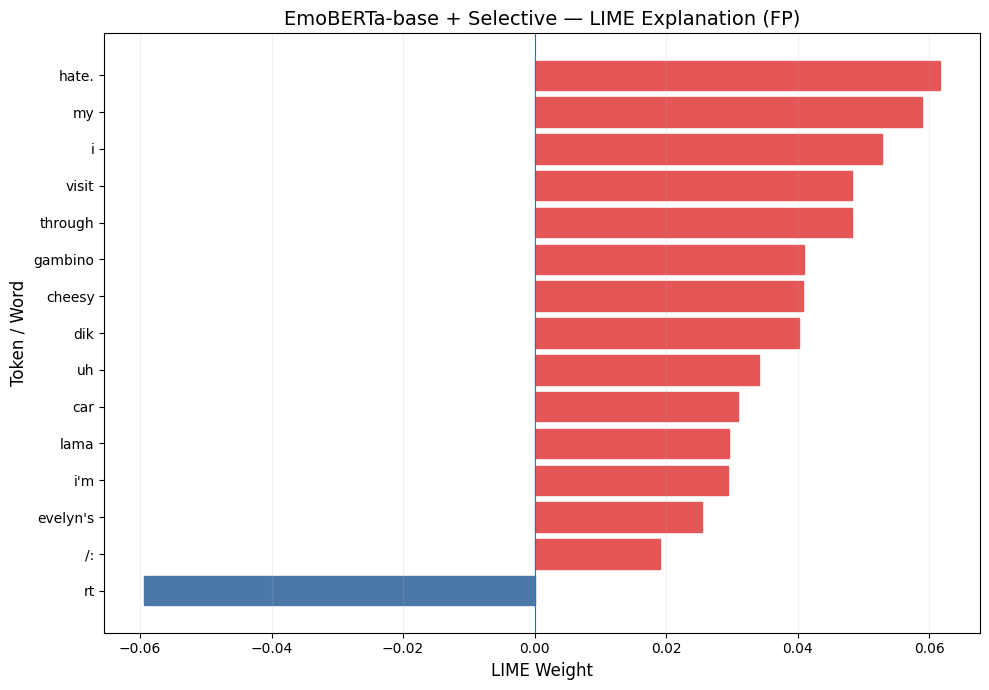

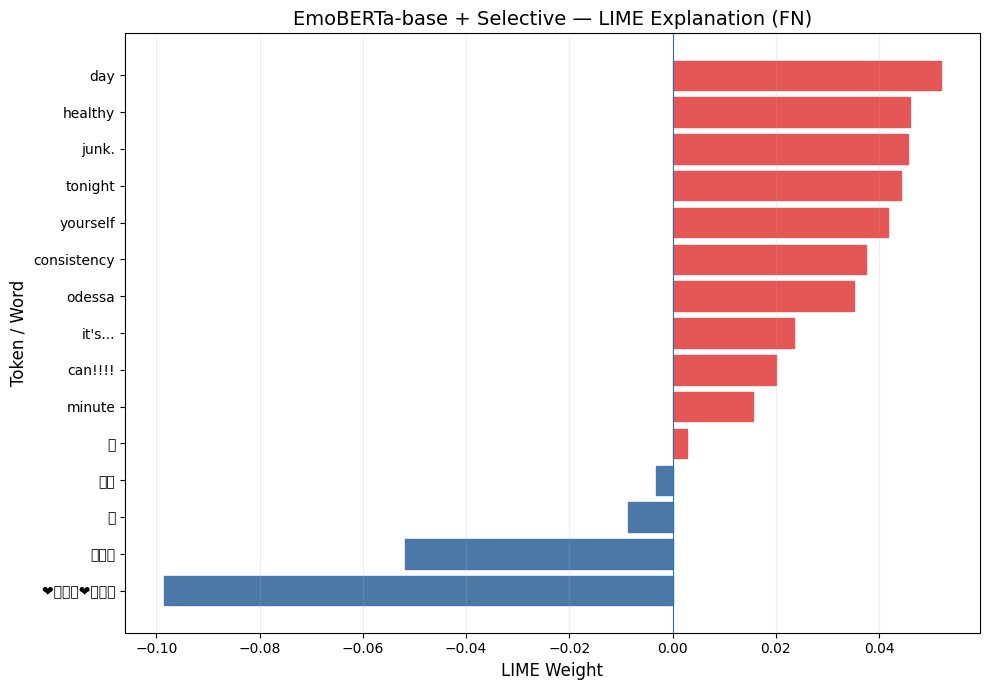


LIME ANALYSIS COMPLETE
✓ TP, TN, FP, FN cases explained
✓ Same trained EmoBERTa model used
✓ Metadata held fixed per user
✓ 1000 LIME perturbations per case
✓ Top 15 features extracted
✓ LIME results saved
✓ HTML explanations saved
✓ Paper-ready LIME plots saved and displayed

LIME output directory: /kaggle/working/emoberta_selective/explainability/lime


In [20]:
# ============================================================
# EXPLAINABILITY — LIME
# EMOBERTA-BASE + SELECTIVE
# LOCAL TOKEN-LEVEL EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from lime.lime_text import LimeTextExplainer
from IPython.display import display, HTML


print("=" * 70)
print("LIME ANALYSIS")
print("EMOBERTA-BASE + SELECTIVE")
print("=" * 70)


# ============================================================
# FIXED LIME SETTINGS
# ============================================================

LIME_SEED = 42
LIME_NUM_FEATURES = 15
LIME_NUM_SAMPLES = 1000
LIME_BATCH_SIZE = 8

np.random.seed(
    LIME_SEED
)

torch.manual_seed(
    LIME_SEED
)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

LIME_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "lime"
)

os.makedirs(
    LIME_DIR,
    exist_ok=True
)


# ============================================================
# MODEL
# ============================================================

model.eval()

for parameter in model.parameters():
    parameter.requires_grad = False

print()
print("✓ EmoBERTa Selective model ready")


# ============================================================
# TEST PREDICTIONS
# ============================================================

labels_np = []
preds_np = []
probs_np = []

with torch.no_grad():

    for batch in test_loader:

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs["logits"]

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]

        predictions = (
            probabilities >= 0.5
        ).long()

        labels_np.extend(
            labels.cpu()
            .numpy()
            .tolist()
        )

        preds_np.extend(
            predictions.cpu()
            .numpy()
            .tolist()
        )

        probs_np.extend(
            probabilities.cpu()
            .numpy()
            .tolist()
        )


labels_np = np.asarray(
    labels_np
)

preds_np = np.asarray(
    preds_np
)

probs_np = np.asarray(
    probs_np
)


print()
print(
    "Test users:",
    len(labels_np)
)


# ============================================================
# DETERMINISTIC TP / TN / FP / FN
# ============================================================

tp_candidates = np.where(
    (labels_np == 1) &
    (preds_np == 1)
)[0]

tn_candidates = np.where(
    (labels_np == 0) &
    (preds_np == 0)
)[0]

fp_candidates = np.where(
    (labels_np == 0) &
    (preds_np == 1)
)[0]

fn_candidates = np.where(
    (labels_np == 1) &
    (preds_np == 0)
)[0]


assert len(tp_candidates) > 0
assert len(tn_candidates) > 0
assert len(fp_candidates) > 0
assert len(fn_candidates) > 0


selected_cases = {

    "TP":
        int(
            tp_candidates[0]
        ),

    "TN":
        int(
            tn_candidates[0]
        ),

    "FP":
        int(
            fp_candidates[0]
        ),

    "FN":
        int(
            fn_candidates[0]
        )
}


print()
print("=" * 70)
print("SELECTED CASES")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print(
        f"{case_name}: "
        f"Test Index = {test_index} | "
        f"True = {labels_np[test_index]} | "
        f"Pred = {preds_np[test_index]} | "
        f"Positive Probability = "
        f"{probs_np[test_index]:.4f}"
    )


# ============================================================
# LIME TEXT ACCESS
# ============================================================
# The same cleaned model_text that was used for EmoBERTa
# tokenization is used for LIME explanations.
# ============================================================

def get_test_text(
    test_index
):

    return str(
        test_emoberta_selective_df.iloc[
            int(test_index)
        ]["model_text"]
    )


# ============================================================
# LIME PREDICTOR
# ============================================================
# Text is perturbed by LIME.
# Metadata remains fixed for the explained user.
# ============================================================

def make_lime_predictor(
    test_index
):

    sample = test_dataset[
        int(test_index)
    ]

    fixed_metadata = (
        sample["metadata"]
        .unsqueeze(0)
        .float()
        .to(device)
    )

    def lime_predict(
        texts
    ):

        all_probabilities = []

        for start in range(
            0,
            len(texts),
            LIME_BATCH_SIZE
        ):

            text_batch = texts[
                start:
                start + LIME_BATCH_SIZE
            ]

            encoded = tokenizer(
                text_batch,
                max_length=MAX_LENGTH,
                truncation=True,
                padding="max_length",
                return_attention_mask=True
            )

            input_ids = torch.tensor(
                encoded["input_ids"],
                dtype=torch.long
            ).to(device)

            attention_mask = torch.tensor(
                encoded["attention_mask"],
                dtype=torch.long
            ).to(device)

            metadata_batch = (
                fixed_metadata
                .expand(
                    len(text_batch),
                    -1
                )
            )

            with torch.no_grad():

                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    metadata=metadata_batch
                )

                logits = outputs["logits"]

                probabilities = torch.softmax(
                    logits.float(),
                    dim=1
                )

            all_probabilities.append(
                probabilities
                .cpu()
                .numpy()
            )

            del input_ids
            del attention_mask
            del metadata_batch
            del outputs
            del logits
            del probabilities

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        return np.vstack(
            all_probabilities
        )

    return lime_predict


# ============================================================
# LIME EXPLAINER
# ============================================================

explainer = LimeTextExplainer(
    class_names=[
        "Negative",
        "Positive"
    ],
    split_expression=r"\s+",
    random_state=LIME_SEED
)

print()
print("✓ LIME explainer ready")


# ============================================================
# RUN LIME FOR FOUR CASES
# ============================================================

all_explanations = {}

print()
print("=" * 70)
print("GENERATING LIME EXPLANATIONS")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print()
    print(
        f"Processing {case_name} "
        f"(test index {test_index})..."
    )

    text = get_test_text(
        test_index
    )

    predictor = make_lime_predictor(
        test_index
    )

    explanation = explainer.explain_instance(
        text,
        predictor,
        labels=(1,),
        num_features=LIME_NUM_FEATURES,
        num_samples=LIME_NUM_SAMPLES
    )

    all_explanations[
        case_name
    ] = explanation

    print(
        f"✓ {case_name} explanation complete"
    )


# ============================================================
# SAVE LIME RESULTS
# ============================================================

all_lime_rows = []

for case_name, explanation in all_explanations.items():

    explanation_list = explanation.as_list(
        label=1
    )

    for rank, (
        word,
        weight
    ) in enumerate(
        explanation_list,
        start=1
    ):

        all_lime_rows.append({

            "case":
                case_name,

            "test_index":
                selected_cases[
                    case_name
                ],

            "true_label":
                int(
                    labels_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "predicted_label":
                int(
                    preds_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "positive_probability":
                float(
                    probs_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "rank":
                rank,

            "word":
                word,

            "lime_weight":
                float(weight)

        })


lime_results_df = pd.DataFrame(
    all_lime_rows
)

lime_csv_path = os.path.join(
    LIME_DIR,
    "emoberta_selective_lime_results.csv"
)

lime_results_df.to_csv(
    lime_csv_path,
    index=False
)


# ============================================================
# DISPLAY + SAVE HTML
# ============================================================

print()
print("=" * 70)
print("LIME EXPLANATIONS")
print("=" * 70)

for case_name, explanation in all_explanations.items():

    print()
    print(
        "=" * 60
    )

    print(
        f"{case_name} — "
        f"LIME LOCAL EXPLANATION"
    )

    print(
        "=" * 60
    )

    display(
        HTML(
            explanation.as_html(
                labels=[1]
            )
        )
    )

    html_path = os.path.join(
        LIME_DIR,
        f"emoberta_selective_lime_{case_name}.html"
    )

    with open(
        html_path,
        "w",
        encoding="utf-8"
    ) as f:

        f.write(
            explanation.as_html(
                labels=[1]
            )
        )


# ============================================================
# PAPER-FRIENDLY LIME BAR PLOTS
# ============================================================

for case_name, explanation in all_explanations.items():

    explanation_list = explanation.as_list(
        label=1
    )

    plot_df = pd.DataFrame(
        explanation_list,
        columns=[
            "word",
            "weight"
        ]
    )

    plot_df = plot_df.sort_values(
        "weight"
    )

    plt.figure(
        figsize=(10, 7)
    )

    bars = plt.barh(
        plot_df["word"],
        plot_df["weight"]
    )

    # Positive contribution
    for bar, weight in zip(
        bars,
        plot_df["weight"]
    ):

        if weight > 0:
            bar.set_color(
                "#E45756"
            )

        else:
            bar.set_color(
                "#4C78A8"
            )

    plt.axvline(
        0,
        linewidth=0.8
    )

    plt.xlabel(
        "LIME Weight",
        fontsize=12
    )

    plt.ylabel(
        "Token / Word",
        fontsize=12
    )

    plt.title(
        f"EmoBERTa-base + Selective — "
        f"LIME Explanation ({case_name})",
        fontsize=14
    )

    plt.grid(
        axis="x",
        alpha=0.20
    )

    plt.tight_layout()

    plot_path = os.path.join(
        LIME_DIR,
        f"emoberta_selective_lime_{case_name}.png"
    )

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ============================================================
# SAVE CASE INFORMATION
# ============================================================

case_info_rows = []

for case_name, test_index in selected_cases.items():

    case_info_rows.append({

        "case":
            case_name,

        "test_index":
            int(test_index),

        "true_label":
            int(
                labels_np[
                    test_index
                ]
            ),

        "predicted_label":
            int(
                preds_np[
                    test_index
                ]
            ),

        "positive_probability":
            float(
                probs_np[
                    test_index
                ]
            ),

        "text_length_characters":
            len(
                get_test_text(
                    test_index
                )
            )

    })


case_info_df = pd.DataFrame(
    case_info_rows
)

case_info_df.to_csv(
    os.path.join(
        LIME_DIR,
        "emoberta_selective_lime_case_information.csv"
    ),
    index=False
)


# ============================================================
# SAVE CONFIGURATION
# ============================================================

lime_config = {

    "model":
        "EmoBERTa-base",

    "cleaning":
        "Selective",

    "dataset":
        "Held-out test set",

    "target":
        "Positive/depression class",

    "representative_cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "case_selection":
        "First matching test example in fixed test order",

    "random_seed":
        LIME_SEED,

    "num_samples":
        LIME_NUM_SAMPLES,

    "num_features":
        LIME_NUM_FEATURES,

    "batch_size":
        LIME_BATCH_SIZE,

    "metadata":
        "Fixed for each explained user",

    "text_perturbation":
        "LIME word-level perturbations",

    "model_training":
        "No additional training"

}

with open(
    os.path.join(
        LIME_DIR,
        "emoberta_selective_lime_config.json"
    ),
    "w"
) as f:

    json.dump(
        lime_config,
        f,
        indent=2
    )


# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("LIME ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ TP, TN, FP, FN cases explained"
)

print(
    "✓ Same trained EmoBERTa model used"
)

print(
    "✓ Metadata held fixed per user"
)

print(
    "✓ 1000 LIME perturbations per case"
)

print(
    "✓ Top 15 features extracted"
)

print(
    "✓ LIME results saved"
)

print(
    "✓ HTML explanations saved"
)

print(
    "✓ Paper-ready LIME plots saved and displayed"
)

print()
print(
    "LIME output directory:",
    LIME_DIR
)